In [1]:
# ============================================================
# Setup: imports, dependencies, and dataset loading
# ============================================================

# Install required library for Word2Vec
!pip install -q gensim

import re
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Suppress warnings for cleaner output
warnings.filterwarnings("ignore")

from IPython.display import display
from datasets import load_dataset
from gensim.models import KeyedVectors

# Sklearn utilities
from sklearn.base import clone
from sklearn.utils import shuffle
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    StratifiedShuffleSplit,
)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Load QEvasion dataset (train/test splits)
dataset = load_dataset("ailsntua/QEvasion")
print(dataset)

# Convert HuggingFace datasets to pandas DataFrames
train_df = dataset["train"].to_pandas()
test_df  = dataset["test"].to_pandas()

# Basic dataset info
print(f"\nTrain size : {len(train_df)}")
print(f"Test size  : {len(test_df)}")
print(f"\nColumns    : {list(train_df.columns)}")

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 3448
    })
    test: Dataset({
        features: ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator1', 'annotator2', 'annotator3', 'inaudible', 'multiple_questions', 'affirmative_questions', 'index', 'clarity_label', 'evasion_label'],
        num_rows: 308
    })
})

Train size : 3448
Test size  : 308

Columns    : ['title', 'date', 'president', 'url', 'question_order', 'interview_question', 'interview_answer', 'gpt3.5_summary', 'gpt3.5_prediction', 'question', 'annotator_id', 'annotator

In [2]:
# ============================================================
# Dataset structure inspection
# ============================================================

# Inspect training set structure
print(train_df.head().to_string())
print("\nDtypes (train):\n", train_df.dtypes)
print("\nMissing values (train):\n", train_df.isnull().sum())

# Minimal structural check for test set (no EDA)
print("\nTest columns:\n", list(test_df.columns))

                                               title                date        president                                                                                       url  question_order                                                                                                                                                                                                                                                                                                                                                                                                                    interview_question                                                                                                                                                                                                                                                                                                                                                                                               


## 1. Exploratory Data Analysis (EDA)

This section provides an initial examination of the QEvasion dataset before preprocessing and modeling, using **only the training set**.

We analyse four main aspects:
- **Label distribution**, to identify class imbalance
- **Text length statistics**, to understand the size of the question and answer fields
- **Vocabulary patterns**, using unigrams, bigrams, and trigrams by label for both answers and questions
- **Speaker distribution**, to examine whether label patterns vary across political figures and may
introduce confounds


Label distribution (train):
                 count  percent (%)
clarity_label                      
Ambivalent        2040        59.16
Clear Reply       1052        30.51
Clear Non-Reply    356        10.32


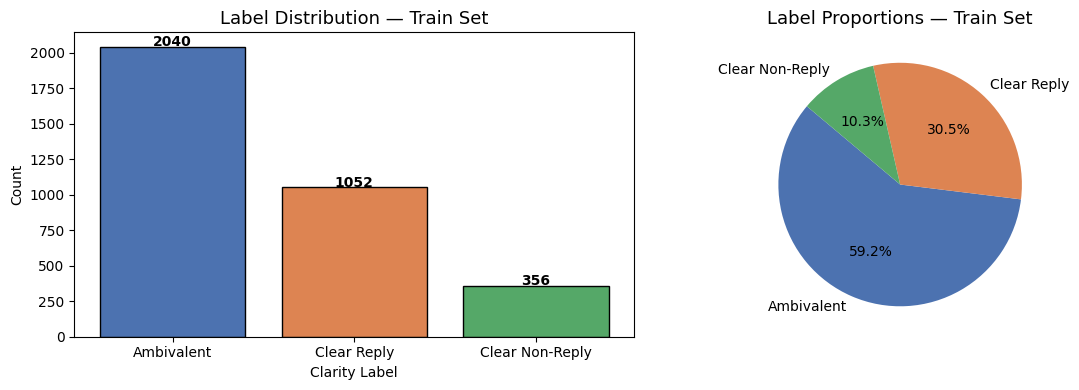

Imbalance ratio (majority/minority): 5.73x


In [3]:
# ============================================================
# 1. Label Distribution (Train Set)
# ============================================================

label_col = "clarity_label"   # label column

label_counts = train_df[label_col].value_counts()
label_pct    = train_df[label_col].value_counts(normalize=True) * 100

print("Label distribution (train):")
print(pd.DataFrame({"count": label_counts, "percent (%)": label_pct.round(2)}))

# Bar chart and pie chart for label distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
axes[0].bar(label_counts.index, label_counts.values,
            color=["#4C72B0", "#DD8452", "#55A868"], edgecolor="black")
axes[0].set_title("Label Distribution — Train Set", fontsize=13)
axes[0].set_xlabel("Clarity Label")
axes[0].set_ylabel("Count")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 5, str(v), ha="center", fontweight="bold")

# Proportion plot
axes[1].pie(label_counts.values,
            labels=label_counts.index,
            autopct="%1.1f%%",
            colors=["#4C72B0", "#DD8452", "#55A868"],
            startangle=140)
axes[1].set_title("Label Proportions — Train Set", fontsize=13)

plt.tight_layout()
plt.savefig("eda_label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Imbalance ratio (majority vs minority)
majority = label_counts.max()
minority = label_counts.min()
print(f"Imbalance ratio (majority/minority): {majority/minority:.2f}x")

In [4]:
# ============================================================
# 2. Text Length Statistics (Train Set)
# ============================================================

# Compute basic length features for questions and answers
train_df["q_word_count"]  = train_df["question"].fillna("").apply(lambda x: len(x.split()))
train_df["a_word_count"]  = train_df["interview_answer"].fillna("").apply(lambda x: len(x.split()))
train_df["q_char_count"]  = train_df["question"].fillna("").apply(len)
train_df["a_char_count"]  = train_df["interview_answer"].fillna("").apply(len)
train_df["qa_word_total"] = train_df["q_word_count"] + train_df["a_word_count"]

print("=== TRAIN — Text Length Summary ===")
print(
    train_df[
        ["q_word_count", "a_word_count", "q_char_count", "a_char_count", "qa_word_total"]
    ].describe().round(1)
)

=== TRAIN — Text Length Summary ===
       q_word_count  a_word_count  q_char_count  a_char_count  qa_word_total
count        3448.0        3448.0        3448.0        3448.0         3448.0
mean           14.5         293.6          84.5        1663.3          308.0
std             8.8         301.5          51.9        1733.3          303.8
min             1.0           1.0           3.0           3.0            2.0
25%             8.0          56.0          47.0         309.0           68.0
50%            12.0         207.0          74.0        1155.5          222.0
75%            19.0         440.0         110.0        2495.0          457.0
max            80.0        2117.0         464.0       12102.0         2140.0


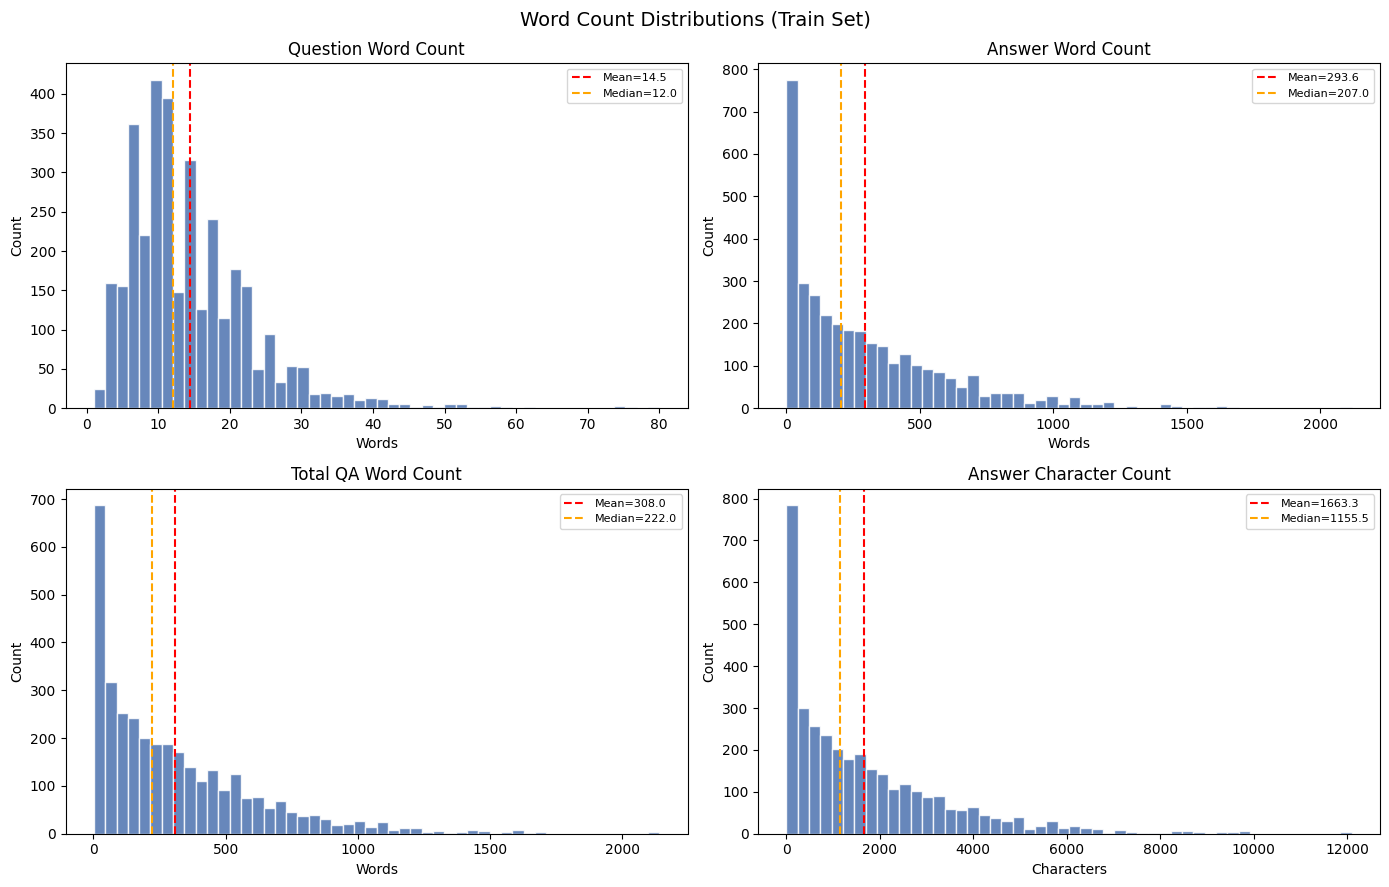

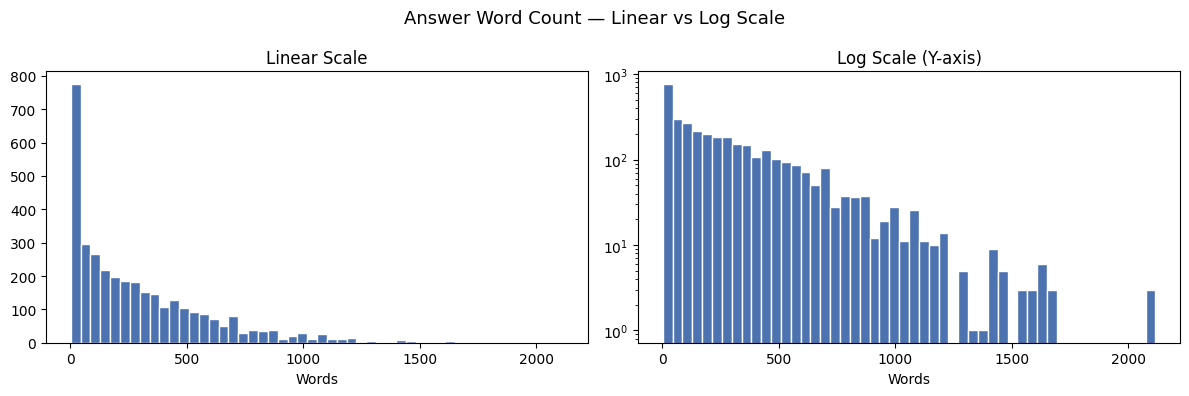

In [5]:
# ============================================================
# 3. Text Length Distributions (Train Set)
# ============================================================

# Histograms for word and character distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Word Count Distributions (Train Set)", fontsize=14)

for ax, col, title in zip(
    axes.flat,
    ["q_word_count", "a_word_count", "qa_word_total", "a_char_count"],
    ["Question Word Count", "Answer Word Count", "Total QA Word Count", "Answer Character Count"]
):
    ax.hist(train_df[col], bins=50, color="#4C72B0", edgecolor="white", alpha=0.85)
    ax.axvline(train_df[col].mean(),   color="red",    linestyle="--", linewidth=1.5, label=f"Mean={train_df[col].mean():.1f}")
    ax.axvline(train_df[col].median(), color="orange", linestyle="--", linewidth=1.5, label=f"Median={train_df[col].median():.1f}")
    ax.set_title(title)
    ax.set_xlabel("Words" if "word" in col.lower() else "Characters")
    ax.set_ylabel("Count")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("eda_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

# Linear vs log-scale distribution for answer length
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Answer Word Count — Linear vs Log Scale", fontsize=13)

axes[0].hist(train_df["a_word_count"], bins=50, color="#4C72B0", edgecolor="white")
axes[0].set_title("Linear Scale")
axes[0].set_xlabel("Words")

axes[1].hist(train_df["a_word_count"], bins=50, color="#4C72B0", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("Log Scale (Y-axis)")
axes[1].set_xlabel("Words")

plt.tight_layout()
plt.show()

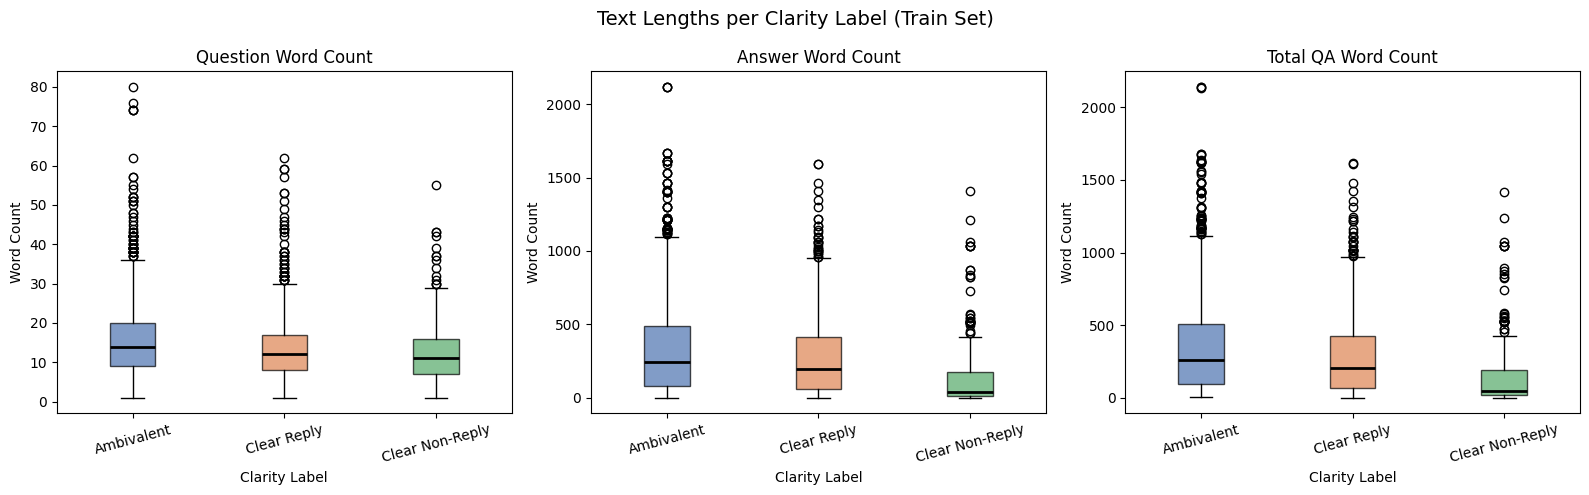

In [6]:
# ============================================================
# 4. Text Length by Label (boxplots)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Text Lengths per Clarity Label (Train Set)", fontsize=14)

for ax, col, title in zip(
    axes,
    ["q_word_count", "a_word_count", "qa_word_total"],
    ["Question Word Count", "Answer Word Count", "Total QA Word Count"]
):
    order = train_df[label_col].value_counts().index.tolist()
    data  = [train_df.loc[train_df[label_col] == lbl, col].values for lbl in order]

    bp = ax.boxplot(data, patch_artist=True, labels=order,
                    medianprops=dict(color="black", linewidth=2))
    colors = ["#4C72B0", "#DD8452", "#55A868"]
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_title(title)
    ax.set_xlabel("Clarity Label")
    ax.set_ylabel("Word Count")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("eda_length_by_label.png", dpi=150, bbox_inches="tight")
plt.show()


In [7]:
# ============================================================
# 5. Per-label descriptive statistics
# ============================================================
print("Answer word count per label (train):")
print(train_df.groupby(label_col)["a_word_count"].describe().round(1))

print("\nQuestion word count per label (train):")
print(train_df.groupby(label_col)["q_word_count"].describe().round(1))

Answer word count per label (train):
                  count   mean    std  min   25%    50%    75%     max
clarity_label                                                         
Ambivalent       2040.0  331.9  319.5  1.0  82.8  243.5  491.8  2117.0
Clear Non-Reply   356.0  137.8  217.4  1.0  12.0   39.5  179.2  1407.0
Clear Reply      1052.0  272.0  269.5  1.0  57.8  194.0  415.2  1592.0

Question word count per label (train):
                  count  mean  std  min  25%   50%   75%   max
clarity_label                                                 
Ambivalent       2040.0  15.3  9.1  1.0  9.0  14.0  20.0  80.0
Clear Non-Reply   356.0  12.6  7.9  1.0  7.0  11.0  16.0  55.0
Clear Reply      1052.0  13.5  8.4  1.0  8.0  12.0  17.0  62.0



Number of distinct presidents/speakers: 4
president
Donald J. Trump    1325
Barack Obama       1010
George W. Bush      714
Joseph R. Biden     399
Name: count, dtype: int64


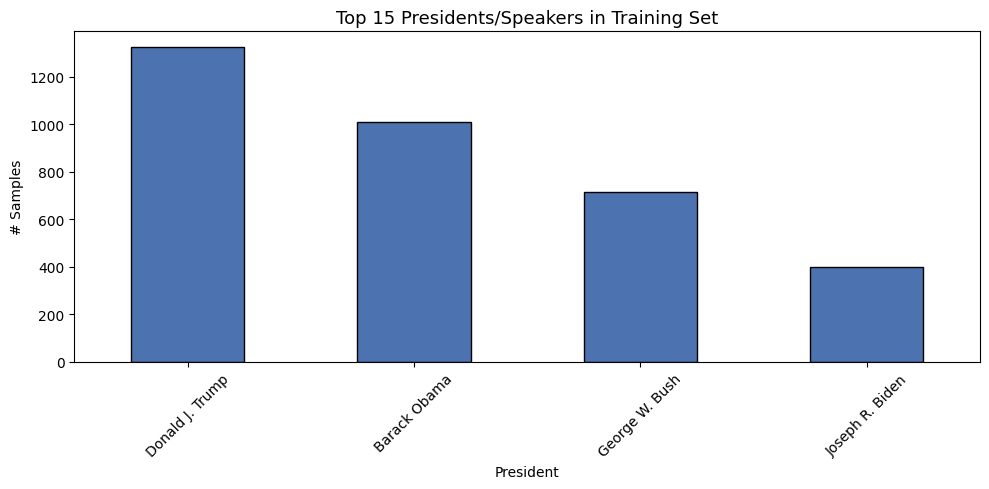

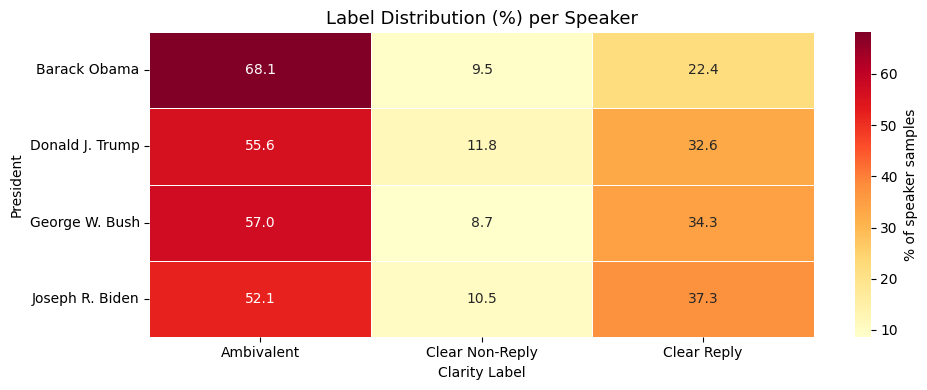

In [8]:
# ============================================================
# 6. President / Source distribution (metadata)
# ============================================================
if "president" in train_df.columns:
    pres_counts = train_df["president"].value_counts()
    print(f"\nNumber of distinct presidents/speakers: {len(pres_counts)}")
    print(pres_counts.head(10))

    fig, ax = plt.subplots(figsize=(10, 5))
    pres_counts.head(15).plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black")
    ax.set_title("Top 15 Presidents/Speakers in Training Set", fontsize=13)
    ax.set_xlabel("President")
    ax.set_ylabel("# Samples")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.savefig("eda_president_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

# Label distribution per president (heatmap) 
if "president" in train_df.columns:
    pivot = (train_df.groupby(["president", label_col])
                     .size()
                     .unstack(fill_value=0))
    pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

    fig, ax = plt.subplots(figsize=(10, max(4, len(pivot_pct) * 0.4)))
    sns.heatmap(pivot_pct, annot=True, fmt=".1f", cmap="YlOrRd",
                linewidths=0.5, ax=ax, cbar_kws={"label": "% of speaker samples"})
    ax.set_title("Label Distribution (%) per Speaker", fontsize=13)
    ax.set_xlabel("Clarity Label")
    ax.set_ylabel("President")
    plt.tight_layout()
    plt.savefig("eda_label_per_president.png", dpi=150, bbox_inches="tight")
    plt.show()

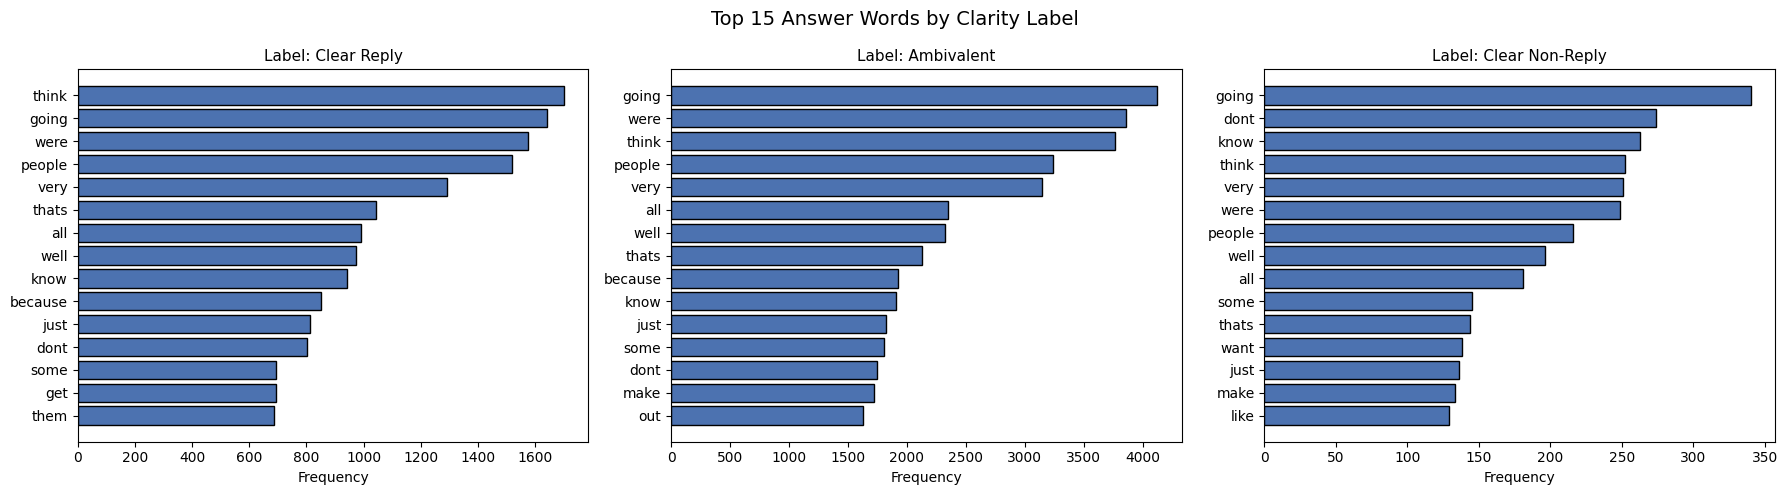

In [9]:
# ============================================================
# 7. Top Words per Label (quick vocabulary peek)
# ============================================================


def top_words(texts, n=20, stopwords=None):
    sw = stopwords or set()
    tokens = []
    for t in texts:
        toks = re.sub(r"[^\w\s]", "", str(t).lower()).split()
        tokens.extend([w for w in toks if w not in sw and len(w) > 2])
    return Counter(tokens).most_common(n)

STOPWORDS = set([
    "the","a","an","and","or","but","in","on","of","to","is","was",
    "it","that","this","for","with","as","be","are","have","he","she",
    "we","they","do","not","at","by","from","i","you","his","her","its",
    "our","their","what","which","who","how","when","where","will","would",
    "can","could","been","had","has","did","said","one","there","about","my"
])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Top 15 Answer Words by Clarity Label", fontsize=14)

for ax, label in zip(axes, train_df[label_col].unique()):
    subset  = train_df.loc[train_df[label_col] == label, "interview_answer"]
    top     = top_words(subset, n=15, stopwords=STOPWORDS)
    words, counts = zip(*top)
    ax.barh(words[::-1], counts[::-1], color="#4C72B0", edgecolor="black")
    ax.set_title(f"Label: {label}", fontsize=11)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("eda_top_words_per_label.png", dpi=150, bbox_inches="tight")
plt.show()


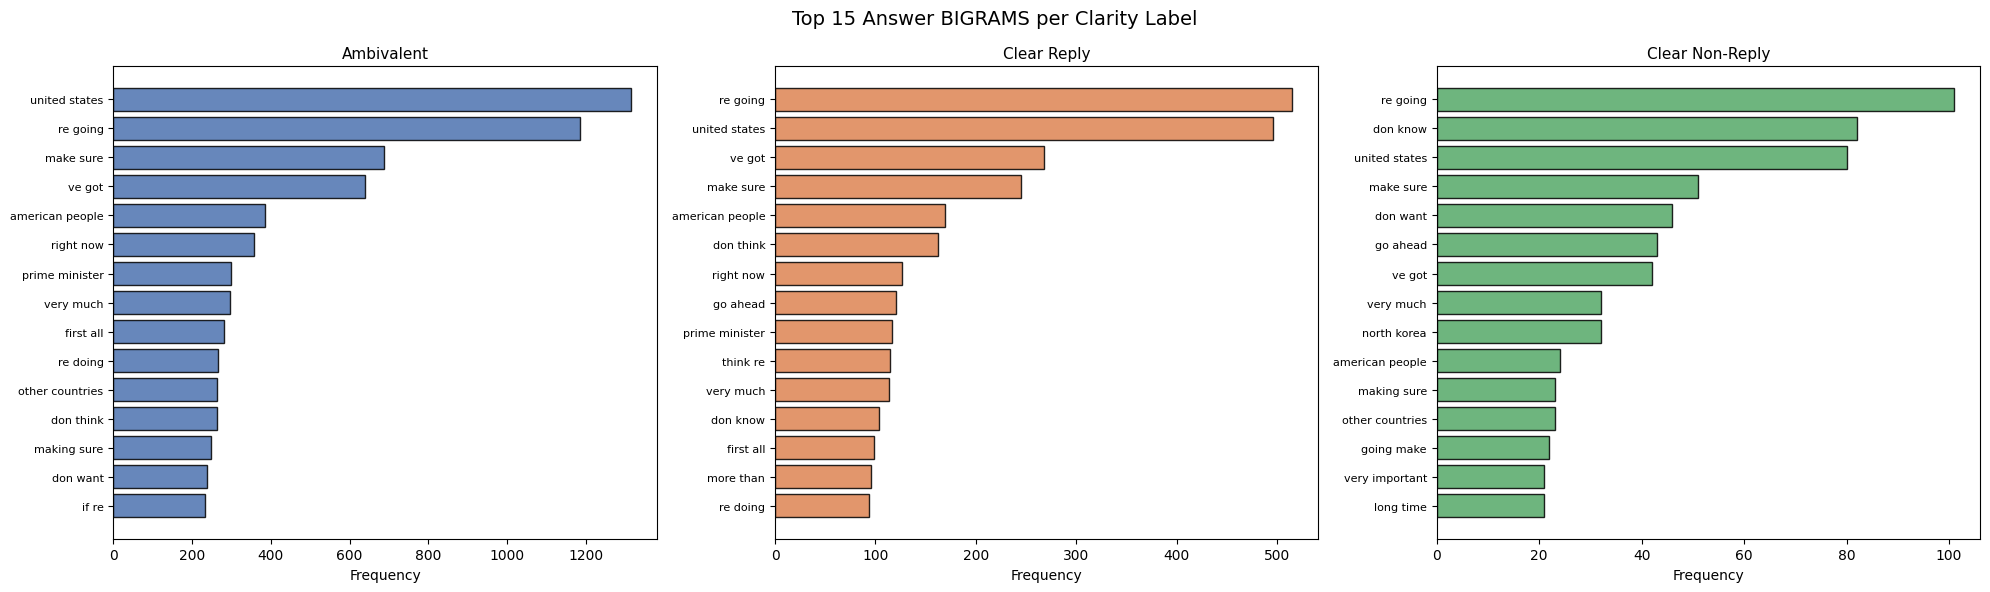

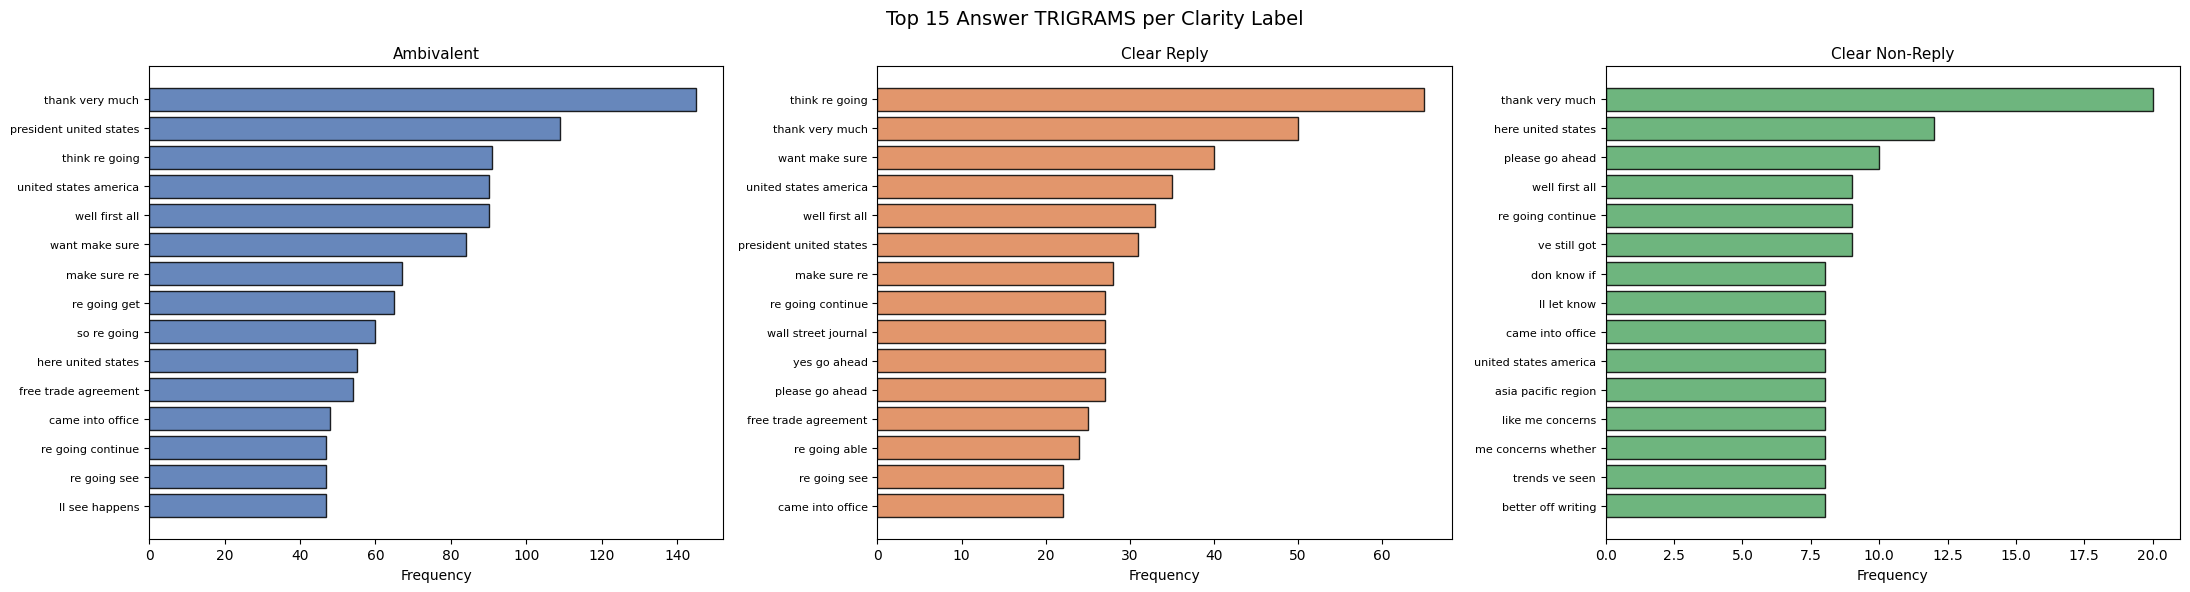

=== Label-Distinctive Bigrams (appear in one label more than others) ===

--- Most distinctive bigrams for 'Ambivalent' ---
  'united states':  +0.0105 vs other labels
  'first all':  +0.0065 vs other labels
  'make sure':  +0.0057 vs other labels
  'if re':  +0.0046 vs other labels
  've got':  +0.0045 vs other labels
  're doing':  +0.0044 vs other labels
  'right now':  +0.0041 vs other labels
  'let me':  +0.0038 vs other labels
  'mr president':  +0.0036 vs other labels
  'very very':  +0.0036 vs other labels

--- Most distinctive bigrams for 'Clear Reply' ---
  'no no':  +0.0095 vs other labels
  'no all':  +0.0082 vs other labels
  'go ahead':  +0.0081 vs other labels
  'yes go':  +0.0076 vs other labels
  'answer yes':  +0.0044 vs other labels
  'more than':  +0.0040 vs other labels
  'no don':  +0.0037 vs other labels
  'no didn':  +0.0036 vs other labels
  'don think':  +0.0035 vs other labels
  'yes yes':  +0.0034 vs other labels

--- Most distinctive bigrams for 'Clear Non-

In [10]:
# ============================================================
# 8. N-gram Analysis per Label
# ============================================================

def get_top_ngrams(corpus, n=2, top_k=15, extra_sw=None):
    """Extract top-k n-grams from a list of texts."""
    sw = list(STOPWORDS)
    if extra_sw:
        sw += extra_sw
    vec = CountVectorizer(
        ngram_range=(n, n),
        stop_words=sw,
        max_features=5000
    ).fit(corpus)
    bag = vec.transform(corpus)
    sum_words = bag.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:top_k]

labels_ordered = ["Ambivalent", "Clear Reply", "Clear Non-Reply"]
colors = ["#4C72B0", "#DD8452", "#55A868"]

# ---- Bigrams ----
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Top 15 Answer BIGRAMS per Clarity Label", fontsize=14)

for ax, label, color in zip(axes, labels_ordered, colors):
    subset = train_df.loc[train_df["clarity_label"] == label, "interview_answer"].fillna("").tolist()
    top = get_top_ngrams(subset, n=2, top_k=15)
    phrases, counts = zip(*top)
    ax.barh(list(phrases)[::-1], list(counts)[::-1], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(f"{label}", fontsize=11)
    ax.set_xlabel("Frequency")
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig("eda_bigrams_per_label.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Trigrams ----
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle("Top 15 Answer TRIGRAMS per Clarity Label", fontsize=14)

for ax, label, color in zip(axes, labels_ordered, colors):
    subset = train_df.loc[train_df["clarity_label"] == label, "interview_answer"].fillna("").tolist()
    top = get_top_ngrams(subset, n=3, top_k=15)
    phrases, counts = zip(*top)
    ax.barh(list(phrases)[::-1], list(counts)[::-1], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(f"{label}", fontsize=11)
    ax.set_xlabel("Frequency")
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig("eda_trigrams_per_label.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Label-distinctive bigrams (TF-IDF difference) ----
print("=== Label-Distinctive Bigrams (appear in one label more than others) ===\n")

from sklearn.feature_extraction.text import TfidfVectorizer

for label in labels_ordered:
    pos = train_df.loc[train_df["clarity_label"] == label, "interview_answer"].fillna("").tolist()
    neg = train_df.loc[train_df["clarity_label"] != label, "interview_answer"].fillna("").tolist()
    
    vec = TfidfVectorizer(ngram_range=(2, 2), stop_words=list(STOPWORDS), max_features=5000)
    vec.fit(pos + neg)
    
    pos_mat = vec.transform(pos).mean(axis=0)
    neg_mat = vec.transform(neg).mean(axis=0)
    
    diff = pos_mat - neg_mat
    diff_arr = diff.A1
    top_idx = diff_arr.argsort()[::-1][:10]
    
    feature_names = vec.get_feature_names_out()
    print(f"--- Most distinctive bigrams for '{label}' ---")
    for idx in top_idx:
        print(f"  '{feature_names[idx]}':  +{diff_arr[idx]:.4f} vs other labels")
    print()

=== Question Field Overview ===
Unique questions (train)  : 3386
Any null questions?       : False


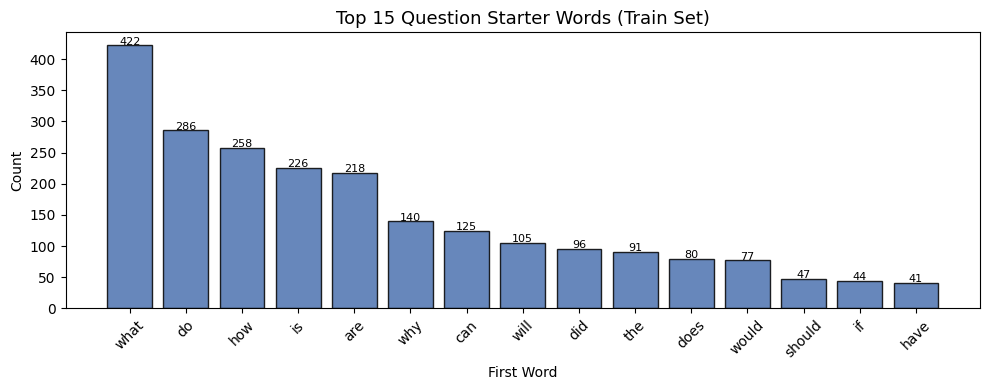

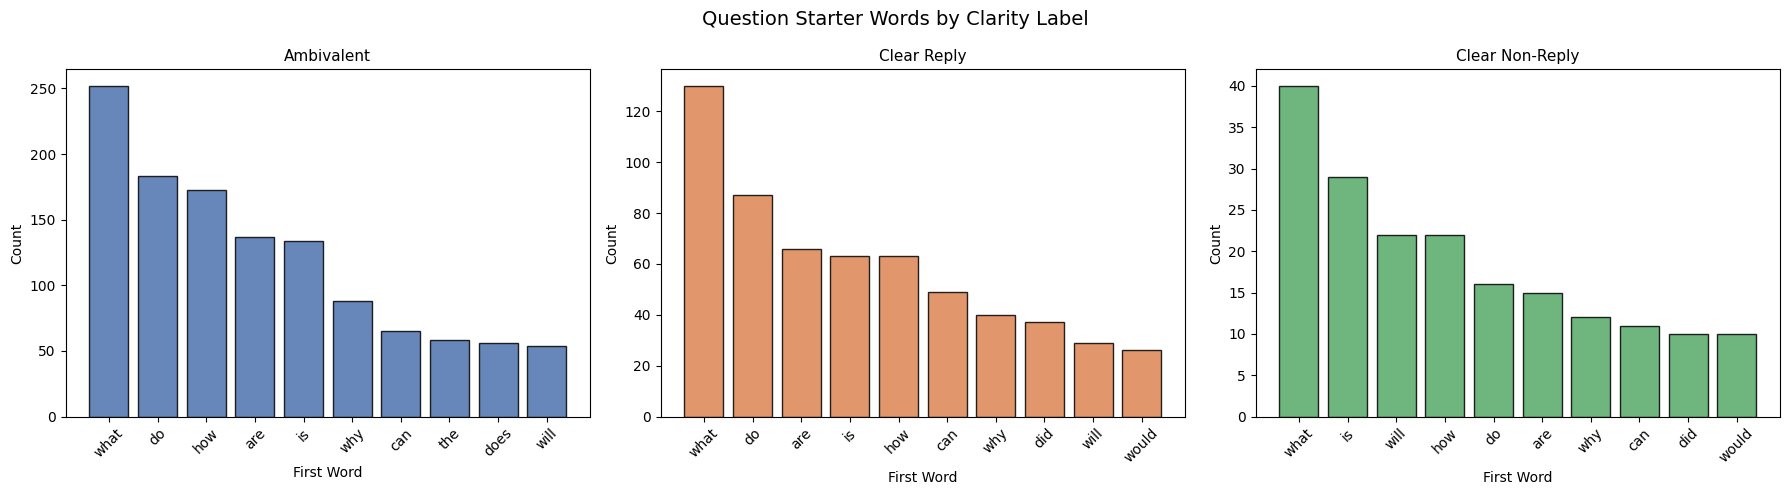

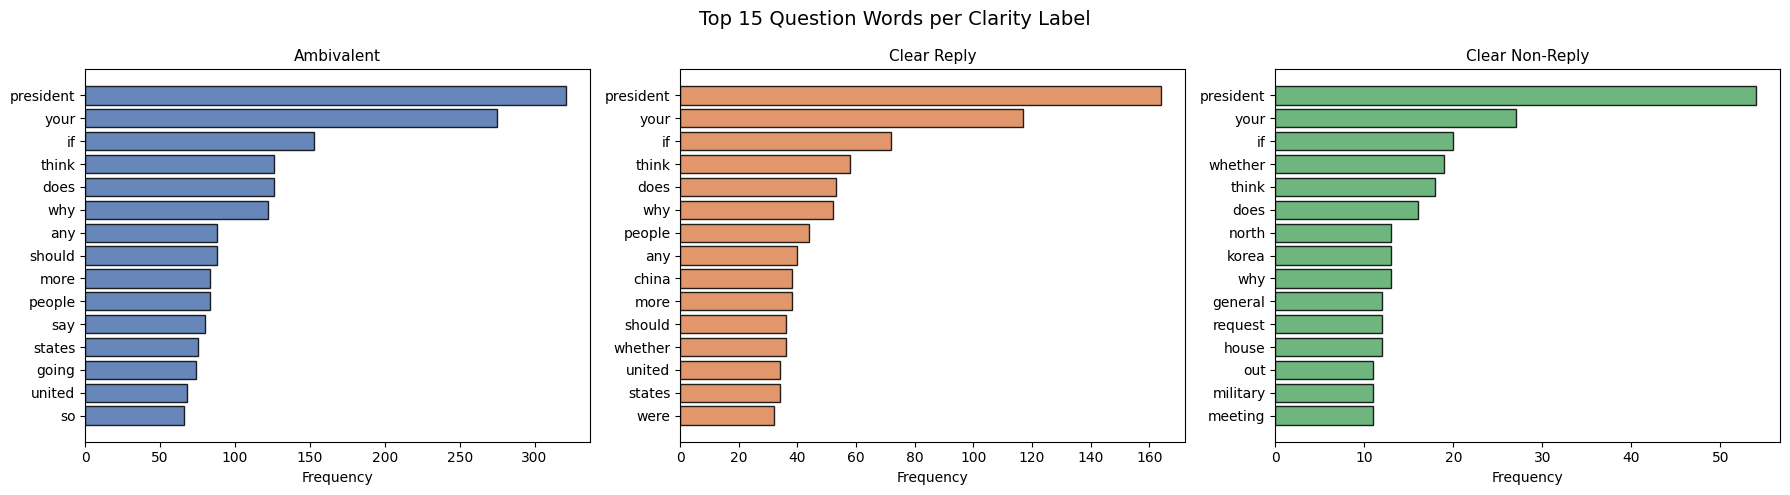

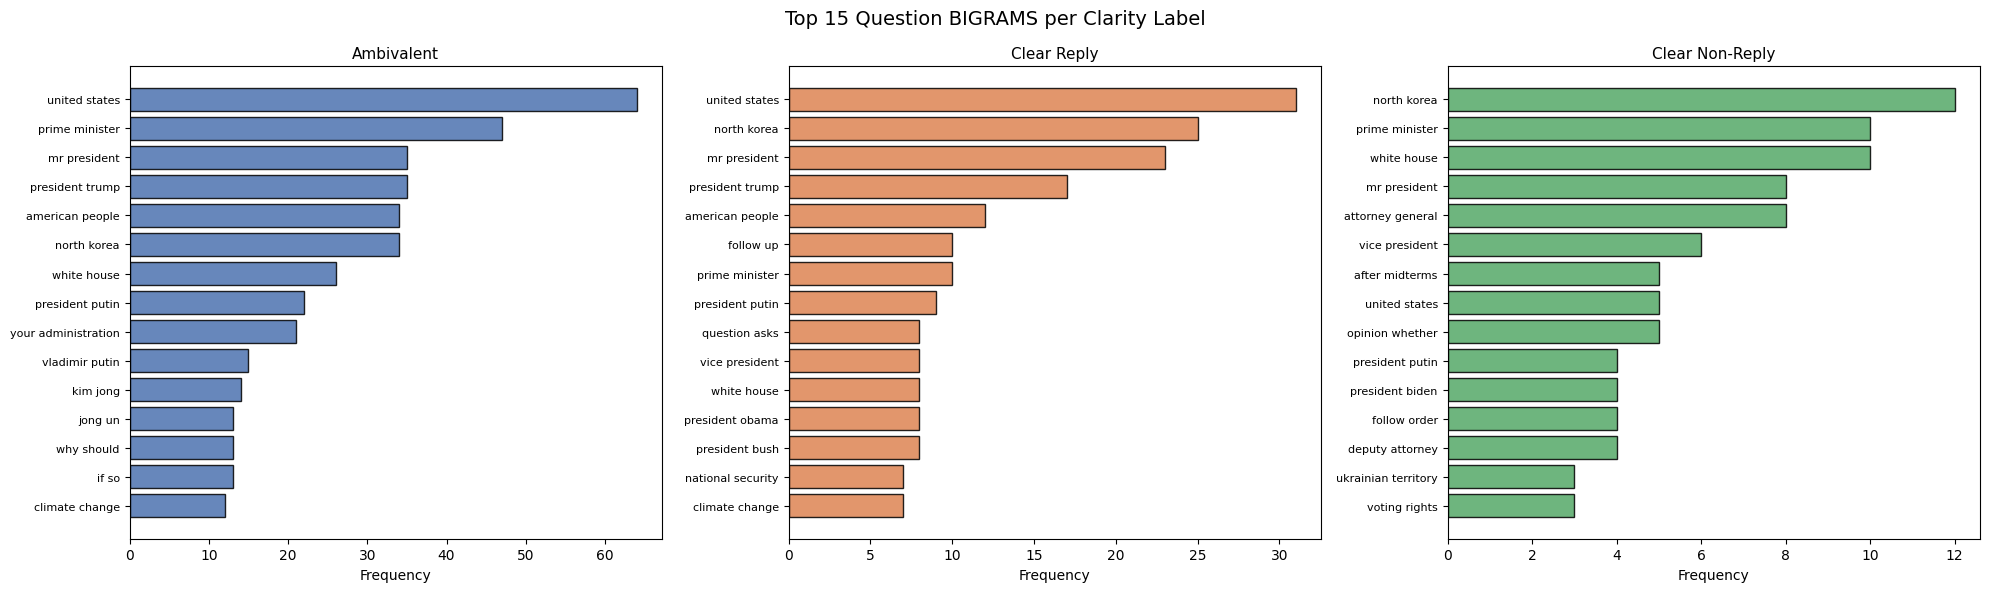


=== Answer/Question Word Count Ratio by Label ===
                  count   mean    std   min   25%    50%    75%     max
clarity_label                                                          
Ambivalent       2040.0  24.01  28.31  0.03  5.82  16.00  31.96  313.00
Clear Non-Reply   356.0  11.62  20.91  0.09  1.19   3.45  12.19  173.40
Clear Reply      1052.0  21.58  25.24  0.04  4.58  13.41  29.80  279.67


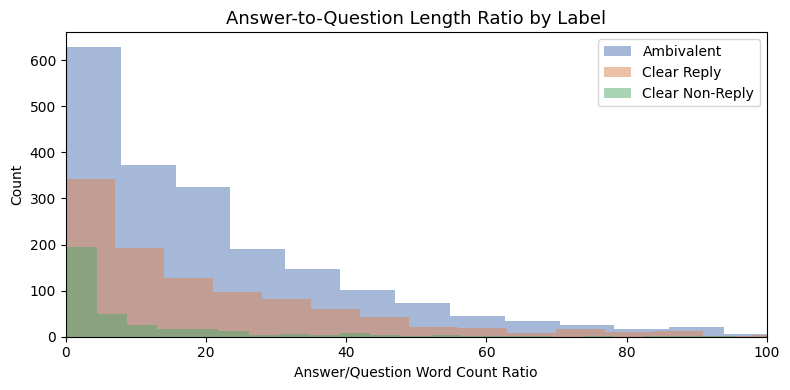


=== interview_question vs question length comparison ===
       q_word_count  iq_word_count
count        3448.0         3448.0
mean           14.5           61.5
std             8.8           59.9
min             1.0            3.0
25%             8.0           22.0
50%            12.0           50.0
75%            19.0           82.0
max            80.0          780.0

Cases where interview_question is >50% longer than question: 2784 (80.7%)


In [11]:
# ============================================================
# 9. Question Field Analysis
# ============================================================

print("=== Question Field Overview ===")
print(f"Unique questions (train)  : {train_df['question'].nunique()}")
print(f"Any null questions?       : {train_df['question'].isnull().any()}")

# First word of each question (e.g. "what", "how", "why")
train_df["q_first_word"] = train_df["question"].fillna("").apply(
    lambda x: x.strip().split()[0].lower().rstrip("?.,") if x.strip() else ""
)

q_first = train_df["q_first_word"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(q_first.index, q_first.values, color="#4C72B0", edgecolor="black", alpha=0.85)
ax.set_title("Top 15 Question Starter Words (Train Set)", fontsize=13)
ax.set_xlabel("First Word")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(q_first.values):
    ax.text(i, v + 1, str(v), ha="center", fontsize=8)

plt.tight_layout()
plt.savefig("eda_question_starters.png", dpi=150, bbox_inches="tight")
plt.show()

# Question starters by label
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Question Starter Words by Clarity Label", fontsize=14)

for ax, label, color in zip(axes, labels_ordered, colors):
    subset = train_df.loc[train_df["clarity_label"] == label, "q_first_word"]
    top = subset.value_counts().head(10)
    ax.bar(top.index, top.values, color=color, edgecolor="black", alpha=0.85)
    ax.set_title(f"{label}", fontsize=11)
    ax.set_xlabel("First Word")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("eda_question_starters_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

# Top question unigrams per label
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Top 15 Question Words per Clarity Label", fontsize=14)

for ax, label, color in zip(axes, labels_ordered, colors):
    subset = train_df.loc[train_df["clarity_label"] == label, "question"].fillna("").tolist()
    top = get_top_ngrams(subset, n=1, top_k=15)
    phrases, counts = zip(*top)
    ax.barh(list(phrases)[::-1], list(counts)[::-1], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(f"{label}", fontsize=11)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("eda_question_words_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

# Top question bigrams per label
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Top 15 Question BIGRAMS per Clarity Label", fontsize=14)

for ax, label, color in zip(axes, labels_ordered, colors):
    subset = train_df.loc[train_df["clarity_label"] == label, "question"].fillna("").tolist()
    top = get_top_ngrams(subset, n=2, top_k=15)
    phrases, counts = zip(*top)
    ax.barh(list(phrases)[::-1], list(counts)[::-1], color=color, edgecolor="black", alpha=0.85)
    ax.set_title(f"{label}", fontsize=11)
    ax.set_xlabel("Frequency")
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig("eda_question_bigrams_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

# Answer-to-question length ratio
train_df["qa_ratio"] = train_df["a_word_count"] / (train_df["q_word_count"] + 1)

print("\n=== Answer/Question Word Count Ratio by Label ===")
print(train_df.groupby("clarity_label")["qa_ratio"].describe().round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for label, color in zip(labels_ordered, colors):
    data = train_df.loc[train_df["clarity_label"] == label, "qa_ratio"]
    ax.hist(data, bins=40, alpha=0.5, label=label, color=color)

ax.set_xlabel("Answer/Question Word Count Ratio")
ax.set_ylabel("Count")
ax.set_title("Answer-to-Question Length Ratio by Label", fontsize=13)
ax.set_xlim(0, 100)
ax.legend()

plt.tight_layout()
plt.savefig("eda_qa_ratio_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

# Compare segmented question vs full interview_question
print("\n=== interview_question vs question length comparison ===")
train_df["iq_word_count"] = train_df["interview_question"].fillna("").apply(lambda x: len(x.split()))
print(train_df[["q_word_count", "iq_word_count"]].describe().round(1))

multi_q = train_df[train_df["iq_word_count"] > train_df["q_word_count"] * 1.5]
print(f"\nCases where interview_question is >50% longer than question: {len(multi_q)} ({len(multi_q)/len(train_df)*100:.1f}%)")

## 2. Preprocessing

This section applies the text preprocessing pipeline used throughout the notebook.

We perform standard normalization steps, including contraction expansion, lowercasing, punctuation removal, and number normalization. We then create two cleaned text versions:
- a **TF-IDF version**, with conservative stopword removal
- a **Word2Vec version**, which preserves the full token sequence

Finally, we evaluate the effect of preprocessing on vocabulary size.

In [12]:
# ============================================================
# 2.1 Contraction Expansion
# ============================================================

# Mapping of common contractions and informal speech forms
CONTRACTIONS = {
    # Full-word contractions first (order matters to avoid incorrect splits)
    "won't": "will not",
    "can't": "cannot",
    "ain't": "is not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "i'm": "i am", 
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "haven't": "have not",
    "hasn't": "has not",
    "hadn't": "had not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "couldn't": "could not",
    "mustn't": "must not",

    # Suffix patterns
    "'re": " are",
    "'d": " would",
    "'ll": " will",
    "'ve": " have",
    "'m": " am",

    # Informal spoken forms
    "gonna": "going to",
    "wanna": "want to",
    "gotta": "got to",
    "kinda": "kind of",
    "sorta": "sort of",
    "y'know": "you know",
    "c'mon": "come on",
    "lemme": "let me",
    "gimme": "give me",
    "dunno": "do not know",
    "ima": "i am going to",
}

def expand_contractions(text):
    text = str(text)
    for contraction, expansion in CONTRACTIONS.items():
        pattern = re.escape(contraction)
        text = re.sub(pattern, expansion, text, flags=re.IGNORECASE)

    # Safety rule for remaining n't forms
    text = re.sub(r"n't\b", " not", text)
    return text

# Quick test
print(expand_contractions("I can't tell you that. We won't discuss it. Obama's policy is going forward."))
# Note: possessives (e.g. "Obama's") are not modified

I cannot tell you that. We will not discuss it. Obama's policy is going forward.


In [13]:
# ============================================================
# 2.2 Lowercasing
# ============================================================

def lowercase(text):
    return str(text).lower()

# Quick test
print(lowercase("President Trump Said: We Are Going To WIN."))

president trump said: we are going to win.


In [14]:
# ============================================================
# 2.3 Punctuation Normalization
# ============================================================

def remove_punctuation(text):
    # Replace non-alphanumeric characters with space
    text = re.sub(r"[^\w\s]", " ", str(text))
    
    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Quick test
print(remove_punctuation("Well... I think—frankly speaking—that we've got to go."))

Well I think frankly speaking that we ve got to go


In [15]:
# ============================================================
# 2.4 Number Normalization
# ============================================================

def normalize_numbers(text):
    # Replace numeric expressions with a placeholder token
    text = re.sub(r'\b\d+\.?\d*\b', 'num_token', str(text))
    return text

print(normalize_numbers("We spent 4.7 billion on 35 programs in 2003."))

We spent num_token billion on num_token programs in num_token.


In [16]:
# ============================================================
# 2.5 Stopword Removal (Selective)
# ============================================================
# TWO VERSIONS:
#   - with_stopwords: removes conservative list (for TF-IDF)
#   - without_stopwords: keeps all content (for Word2Vec,
#     which handles common words via its own training dynamics)

CONSERVATIVE_STOPWORDS = set([
    # Articles
    "a", "an", "the",

    # Prepositions
    "in", "on", "at", "to", "for", "of", "with", "by",
    "from", "as", "into", "through", "about", "against",
    "between", "during", "without", "before", "after",
    "above", "below", "up", "down", "out", "off",

    # Conjunctions
    "and", "or", "but", "so", "yet", "both", "either",
    "neither", "nor", "although", "because", "since",
    "while", "if", "than", "that", "which", "who",

    # Generic pronouns (excluding I/we/you)
    "it", "its", "this", "these", "those", "there",
    "here", "then", "thus", "such",

    # High-frequency fillers
    "also", "just", "very", "too", "much", "many",
    "well", "really", "quite", "actually", "basically",
    "okay", "oh", "um", "uh", "yeah", "yes"
])

# NOTE: negations and modal verbs are intentionally kept (e.g. "not", "will", "should")

def remove_stopwords(text, stopwords=CONSERVATIVE_STOPWORDS):
    tokens = text.split()
    return " ".join([t for t in tokens if t not in stopwords])

test_sent = "i think we should not discuss that well actually i believe it is not the right time"
print(remove_stopwords(test_sent))

i think we should not discuss i believe is not right time


In [17]:
# ============================================================
# 2.6  Whitespace Cleanup 
# ============================================================

def clean_whitespace(text):
    return re.sub(r'\s+', ' ', str(text)).strip()

In [18]:
# ============================================================
# 2.7 Full Preprocessing Pipeline
# ------------------------------------------------------------
# We create TWO versions of the cleaned text:
#
# Version A: question_clean / answer_clean
#   → Used for Word2Vec (no stopword removal)
#   → Preserves the full token sequence before averaging embeddings
#
# Version B: question_clean_nosw / answer_clean_nosw
#   → Used for TF-IDF (with conservative stopword removal)
#   → Reduces noise from high-frequency function words
# ============================================================

def full_preprocess(text, remove_sw=False):
    text = expand_contractions(text)
    text = lowercase(text)
    text = normalize_numbers(text)
    text = remove_punctuation(text)
    # text = clean_whitespace(text)
    if remove_sw:
        text = remove_stopwords(text)
    text = clean_whitespace(text)
    return text

# Apply preprocessing to both train and test sets
for df in [train_df, test_df]:

    # Version A (Word2Vec)
    df["question_clean"]         = df["question"].apply(lambda x: full_preprocess(x, remove_sw=False))
    df["answer_clean"]           = df["interview_answer"].apply(lambda x: full_preprocess(x, remove_sw=False))

    # Version B (TF-IDF)
    df["question_clean_nosw"]    = df["question"].apply(lambda x: full_preprocess(x, remove_sw=True))
    df["answer_clean_nosw"]      = df["interview_answer"].apply(lambda x: full_preprocess(x, remove_sw=True))

print("Preprocessing complete.")
print(f"Train: {len(train_df)} rows | Test: {len(test_df)} rows")

Preprocessing complete.
Train: 3448 rows | Test: 308 rows


In [19]:
# ============================================================
# 2.8 Verify Preprocessing Quality
# ============================================================

# Inspect a few examples before and after preprocessing
print("=== BEFORE vs AFTER preprocessing (3 examples) ===\n")

for i in [0, 5, 100]:
    row = train_df.iloc[i]
    print(f"--- Example {i} | Label: {row['clarity_label']} ---")
    print(f"[ORIGINAL Q]  : {row['question'][:200]}")
    print(f"[CLEAN Q]     : {row['question_clean'][:200]}")
    print(f"[ORIGINAL A]  : {row['interview_answer'][:300]}")
    print(f"[CLEAN A]     : {row['answer_clean'][:300]}")
    print(f"[CLEAN A nosw]: {row['answer_clean_nosw'][:300]}")
    print()

=== BEFORE vs AFTER preprocessing (3 examples) ===

--- Example 0 | Label: Clear Reply ---
[ORIGINAL Q]  : How would you respond to the accusation that the United States is containing China while pushing for diplomatic talks?
[CLEAN Q]     : how would you respond to the accusation that the united states is containing china while pushing for diplomatic talks
[ORIGINAL A]  : Well, look, first of all, theI am sincere about getting the relationship right. And one of the things that is going on now is, China is beginning to change some of the rules of the game, in terms of trade and other issues.And so one of the things we talked about, for example, is that they're now tal
[CLEAN A]     : well look first of all thei am sincere about getting the relationship right and one of the things that is going on now is china is beginning to change some of the rules of the game in terms of trade and other issues and so one of the things we talked about for example is that they are now talking ab
[CLEAN

In [20]:
# ============================================================
# 2.9 Vocabulary Size Before vs After
# ============================================================

def get_vocab(series):
    tokens = []
    for text in series:
        tokens.extend(str(text).split())
    return set(tokens)

# Vocabulary size at each preprocessing stage
vocab_raw        = get_vocab(train_df["interview_answer"])
vocab_clean      = get_vocab(train_df["answer_clean"])
vocab_clean_nosw = get_vocab(train_df["answer_clean_nosw"])

print(f"Vocabulary size — RAW answers         : {len(vocab_raw):,}")
print(f"Vocabulary size — CLEAN (no SW removal): {len(vocab_clean):,}")
print(f"Vocabulary size — CLEAN (with SW removal): {len(vocab_clean_nosw):,}")
print(f"\nVocab reduction (raw → clean)         : {(1 - len(vocab_clean)/len(vocab_raw))*100:.1f}%")
print(f"Vocab reduction (raw → clean+nosw)    : {(1 - len(vocab_clean_nosw)/len(vocab_raw))*100:.1f}%")

Vocabulary size — RAW answers         : 34,782
Vocabulary size — CLEAN (no SW removal): 13,159
Vocabulary size — CLEAN (with SW removal): 13,088

Vocab reduction (raw → clean)         : 62.2%
Vocab reduction (raw → clean+nosw)    : 62.4%


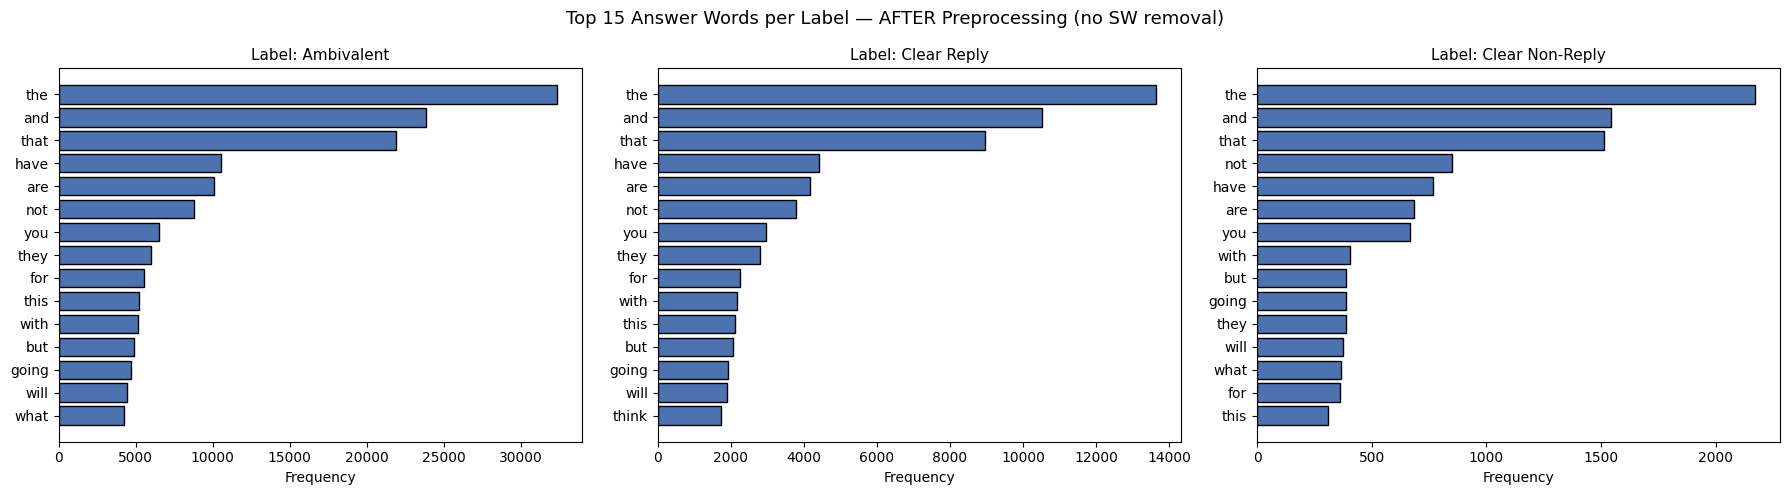

In [21]:
# ============================================================
# 2.10 Top Tokens per Label After Preprocessing
# ============================================================

def top_words_clean(texts, n=15):
    tokens = []
    for t in texts:
        tokens.extend(str(t).split())
    # Exclude placeholder token from visualization
    tokens = [t for t in tokens if t != "num_token" and len(t) > 2]
    return Counter(tokens).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Top 15 Answer Words per Label — AFTER Preprocessing (no SW removal)", fontsize=13)

for ax, label in zip(axes, ["Ambivalent", "Clear Reply", "Clear Non-Reply"]):
    subset = train_df.loc[train_df["clarity_label"] == label, "answer_clean"]
    top    = top_words_clean(subset, n=15)
    if top:
        words, counts = zip(*top)
        ax.barh(words[::-1], counts[::-1], color="#4C72B0", edgecolor="black")
    ax.set_title(f"Label: {label}", fontsize=11)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("preprocessing_top_words_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Input Construction

This section defines how each sample is represented before feature extraction.

Because clarity is a property of the **question–answer pair**, both fields are incorporated into the model input.

- For **TF-IDF**, we combine the cleaned question and answer into a single text string using a `[SEP]` token to mark the boundary between them.
- For **Word2Vec**, the cleaned question and answer are preserved separately so they can later be averaged independently and concatenated into a joint representation.

This design allows both models to use the same underlying information while preserving the structure needed by each representation.

In [22]:
# ============================================================
# 3. Input Construction
# ------------------------------------------------------------
# Clarity is a property of the question–answer pair, so both
# fields are included in the model input.
#
# We construct two input views:
# - input_tfidf: question_clean_nosw + [SEP] + answer_clean_nosw
# - input_w2v:   question_clean + answer_clean
#
# [SEP] is used only in the TF-IDF input to mark the boundary
# between question and answer and avoid cross-boundary n-grams.
# ============================================================

SEP = "[SEP]"

for df in [train_df, test_df]:
    # TF-IDF input (stopword-removed version)
    df["input_tfidf"] = (
        df["question_clean_nosw"] + " " + SEP + " " + df["answer_clean_nosw"]
    )

    # Combined cleaned text view for inspection / length analysis
    df["input_w2v"] = (
        df["question_clean"] + " " + df["answer_clean"]
    )

print("Input construction complete.")
print(f"Train: {len(train_df)} inputs | Test: {len(test_df)} inputs")

Input construction complete.
Train: 3448 inputs | Test: 308 inputs


In [23]:
# ============================================================
# 3.1 Verify Input Construction
# ============================================================

# Inspect a few sample inputs
print("=== Sample inputs — TF-IDF version ===\n")
for i in [0, 5, 100]:
    row = train_df.iloc[i]
    print(f"Label: {row['clarity_label']}")
    print(f"  {row['input_tfidf'][:300]}")
    print()

print("=== Sample inputs — Word2Vec version ===\n")
for i in [0, 5, 100]:
    row = train_df.iloc[i]
    print(f"Label: {row['clarity_label']}")
    print(f"  {row['input_w2v'][:300]}")
    print()

# Sanity check: [SEP] should appear in every TF-IDF input
assert train_df["input_tfidf"].str.contains(r"\[SEP\]").all(), \
    "ERROR: [SEP] token missing from some training inputs!"
assert test_df["input_tfidf"].str.contains(r"\[SEP\]").all(), \
    "ERROR: [SEP] token missing from some test inputs!"
print("Sanity check passed: [SEP] present in all TF-IDF inputs.")

# Token length statistics of constructed inputs
train_df["input_tfidf_len"] = train_df["input_tfidf"].apply(lambda x: len(x.split()))
train_df["input_w2v_len"]   = train_df["input_w2v"].apply(lambda x: len(x.split()))

print("\nInput token length statistics (train):")
print(train_df[["input_tfidf_len", "input_w2v_len"]].describe().round(1))

=== Sample inputs — TF-IDF version ===

Label: Clear Reply
  how would you respond accusation united states is containing china pushing diplomatic talks [SEP] look first all thei am sincere getting relationship right one things is going now is china is beginning change some rules game terms trade other issues one things we talked example is they are now talki

Label: Ambivalent
  is danger cold war [SEP] i hope i get see mr xi sooner later i have spent more time him any other world leader has sum total over last num_token years i hope we get see him again soon no lookfor example one things we did india we provided new path s going save everybody money increase third worldthe

Label: Ambivalent
  what should americans expect congress relates abortion rights midterms [SEP] i do not think they can expect anything other we are going maintain our positions i am not going get more questions i should not even have answered your question

=== Sample inputs — Word2Vec version ===

Label: Clear 

In [24]:
# ============================================================
# 3.2 Train / Validation Split
# ------------------------------------------------------------
# A stratified 15% validation split is used for development
# evaluation, while the test set remains untouched until the
# final submission stage.
# ============================================================

train_split, val_split = train_test_split(
    train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_df["clarity_label"]
)

print(f"train_split : {len(train_split)} samples")
print(f"val_split   : {len(val_split)} samples")

print("\nLabel distribution — train_split:")
print(train_split["clarity_label"].value_counts(normalize=True).mul(100).round(1))

print("\nLabel distribution — val_split:")
print(val_split["clarity_label"].value_counts(normalize=True).mul(100).round(1))

train_split : 2930 samples
val_split   : 518 samples

Label distribution — train_split:
clarity_label
Ambivalent         59.2
Clear Reply        30.5
Clear Non-Reply    10.3
Name: proportion, dtype: float64

Label distribution — val_split:
clarity_label
Ambivalent         59.1
Clear Reply        30.5
Clear Non-Reply    10.4
Name: proportion, dtype: float64


## 4. Feature Extraction

This section transforms the cleaned text into numerical representations for model training.

We compare two feature extraction approaches:
- **TF-IDF**, using n-gram features to capture lexical and phrase-level patterns
- **Word2Vec**, using pretrained embeddings to build dense vector representations of the question–answer pair

The goal is to compare a sparse lexical representation against a dense embedding-based one, while keeping the downstream classifier fixed.

### TF-IDF Feature Extraction

In [25]:
# ============================================================
# 4.1 TF-IDF Feature Extraction
# ------------------------------------------------------------
# Final TF-IDF configuration:
#
# ngram_range=(1, 3):
#   Include unigrams, bigrams, and trigrams to capture
#   phrase-level patterns (e.g. "i think", "i cannot"),
#   which were shown in EDA to be more discriminative than
#   unigrams alone.
#
# max_features=120000:
#   Increased to retain more n-gram features after adding
#   bigrams and trigrams, balancing representation richness
#   with computational cost.
#
# min_df=2:
#   Removes very rare n-grams that are unlikely to generalize.
#
# sublinear_tf=True:
#   Applies log scaling to term frequency to reduce the impact
#   of repeated words in longer answers.
#
# IMPORTANT:
# The vectorizer is fit ONLY on train_split to avoid data leakage.
# ============================================================

TFIDF_PARAMS = {
    "ngram_range": (1, 3),
    "max_features": 120000,
    "min_df": 2,
    "sublinear_tf": True
}

tfidf_vectorizer = TfidfVectorizer(**TFIDF_PARAMS)

# Fit on training split only
X_train_tfidf = tfidf_vectorizer.fit_transform(train_split["input_tfidf"])

# Transform validation and test using the learned vocabulary
X_val_tfidf   = tfidf_vectorizer.transform(val_split["input_tfidf"])
X_test_tfidf  = tfidf_vectorizer.transform(test_df["input_tfidf"])

# Labels
y_train = train_split["clarity_label"].values
y_val   = val_split["clarity_label"].values

print(f"TF-IDF matrix shapes:")
print(f"  X_train_tfidf : {X_train_tfidf.shape}")
print(f"  X_val_tfidf   : {X_val_tfidf.shape}")
print(f"  X_test_tfidf  : {X_test_tfidf.shape}")
print(f"  Vocabulary size learned: {len(tfidf_vectorizer.vocabulary_):,}")

TF-IDF matrix shapes:
  X_train_tfidf : (2930, 120000)
  X_val_tfidf   : (518, 120000)
  X_test_tfidf  : (308, 120000)
  Vocabulary size learned: 120,000


### Word2Vec Feature Extraction

In [26]:
# ============================================================
# 4.2 Word2Vec Feature Extraction — Setup
# ------------------------------------------------------------
# We use pretrained Google News Word2Vec embeddings (300d),
# loaded from a Kaggle-provided KeyedVectors file.
# ============================================================

model_path = "/kaggle/input/datasets/spyrosbenekis/word2vec-google-news-300/word2vec_model/word2vec-google-news-300.kv"

print("Loading Word2Vec model...")
wv = KeyedVectors.load(model_path, mmap='r')
print(f"Loaded. Vocabulary size: {len(wv)}")
print(f"Vector dimension: {wv.vector_size}")

Loading Word2Vec model...
Loaded. Vocabulary size: 3000000
Vector dimension: 300


In [27]:
# ============================================================
# 4.3 Word2Vec Vocabulary Coverage Check
# ------------------------------------------------------------
# Estimate how much of the training vocabulary is covered by
# the pretrained embedding model.
# ============================================================

all_tokens = []
for text in train_split["input_w2v"]:
    all_tokens.extend(str(text).lower().split())

unique_tokens = set(all_tokens)
covered = sum(1 for t in unique_tokens if t in wv)

print(f"Unique tokens in train: {len(unique_tokens)}")
print(f"Covered by W2V vocab : {covered} ({100*covered/len(unique_tokens):.1f}%)")
print(f"OOV tokens           : {len(unique_tokens) - covered}")

Unique tokens in train: 13408
Covered by W2V vocab : 12107 (90.3%)
OOV tokens           : 1301


In [28]:
# ============================================================
# 4.4 Word2Vec Representation Construction (600d)
# ------------------------------------------------------------
# Question and answer are averaged separately into 300d vectors
# and then concatenated into a 600d representation.
# This preserves their distinct roles in the QA pair.
# ============================================================

EMBEDDING_DIM = wv.vector_size  # 300

def text_to_avg_vector(text, embeddings):
    tokens = str(text).split()
    vectors = [embeddings[token] for token in tokens if token in embeddings]
    if vectors:
        return np.mean(vectors, axis=0).astype(np.float32)
    # Return zeros if all tokens are OOV
    return np.zeros(EMBEDDING_DIM, dtype=np.float32)

def qa_to_concat_vector(q_text, a_text, embeddings):
    q_vec = text_to_avg_vector(q_text, embeddings)
    a_vec = text_to_avg_vector(a_text, embeddings)
    return np.concatenate([q_vec, a_vec])  # shape: (600,)

# Build matrices from separate question and answer columns
print("Building 600d concatenated Q+A Word2Vec representations...")
print("  Processing train_split...")
X_train_w2v = np.vstack([
    qa_to_concat_vector(row["question_clean"], row["answer_clean"], wv)
    for _, row in train_split.iterrows()
])

print("  Processing val_split...")
X_val_w2v = np.vstack([
    qa_to_concat_vector(row["question_clean"], row["answer_clean"], wv)
    for _, row in val_split.iterrows()
])

print("  Processing test_df...")
X_test_w2v = np.vstack([
    qa_to_concat_vector(row["question_clean"], row["answer_clean"], wv)
    for _, row in test_df.iterrows()
])

print(f"\nWord2Vec matrix shapes (600d = 300d Q + 300d A):")
print(f"  X_train_w2v : {X_train_w2v.shape}")
print(f"  X_val_w2v   : {X_val_w2v.shape}")
print(f"  X_test_w2v  : {X_test_w2v.shape}")

# OOV analysis on the training split
total_q, oov_q = 0, 0
total_a, oov_a = 0, 0
for _, row in train_split.iterrows():
    q_toks = str(row["question_clean"]).split()
    a_toks = str(row["answer_clean"]).split()
    total_q += len(q_toks)
    total_a += len(a_toks)
    oov_q += sum(1 for t in q_toks if t not in wv)
    oov_a += sum(1 for t in a_toks if t not in wv)

print(f"\nOOV analysis (train_split):")
print(f"  Question tokens: {total_q:,}  OOV: {oov_q:,}  ({oov_q/total_q*100:.1f}%)")
print(f"  Answer tokens  : {total_a:,}  OOV: {oov_a:,}  ({oov_a/total_a*100:.1f}%)")

print("\n" + "="*50)
print("STEP 4 COMPLETE — Feature matrices ready:")
print(f"  TF-IDF   → X_train_tfidf {X_train_tfidf.shape}")
print(f"  Word2Vec → X_train_w2v   {X_train_w2v.shape}  ← 600d")
print(f"  Labels   → y_train {y_train.shape}, y_val {y_val.shape}")
print("="*50)

Building 600d concatenated Q+A Word2Vec representations...
  Processing train_split...
  Processing val_split...
  Processing test_df...

Word2Vec matrix shapes (600d = 300d Q + 300d A):
  X_train_w2v : (2930, 600)
  X_val_w2v   : (518, 600)
  X_test_w2v  : (308, 600)

OOV analysis (train_split):
  Question tokens: 43,289  OOV: 4,558  (10.5%)
  Answer tokens  : 909,169  OOV: 113,045  (12.4%)

STEP 4 COMPLETE — Feature matrices ready:
  TF-IDF   → X_train_tfidf (2930, 120000)
  Word2Vec → X_train_w2v   (2930, 600)  ← 600d
  Labels   → y_train (2930,), y_val (518,)


## 5. Model Training and Evaluation

In this section, we train Logistic Regression models using both TF-IDF and Word2Vec features.

To ensure a fair comparison, the same classifier is used for both representations, with hyperparameters tuned on the validation set using **macro F1-score** as the primary metric.

We evaluate performance using classification reports and confusion matrices, and additionally use cross-validation to assess robustness.

This setup allows us to compare sparse lexical features (TF-IDF) against dense embedding-based features (Word2Vec) under consistent conditions.

In [29]:
# ============================================================
# 5.1 Hyperparameter Tuning — TF-IDF + Logistic Regression
# ------------------------------------------------------------
# We tune Logistic Regression over:
# - C: inverse regularization strength
# - penalty / solver pairs: L2 + lbfgs, L1 + saga
#
# class_weight="balanced" is used to account for class imbalance,
# and macro F1 is the selection metric on val_split.
# ============================================================

C_values  = [0.01, 0.1,0.5, 1.0,1.5, 2.0 ,3.0, 5.0, 10.0, 100.0]

penalties = [("l2", "lbfgs"), ("l1", "saga")]


print("=" * 65)
print("TF-IDF + Logistic Regression — Hyperparameter Search")
print("=" * 65)
print(f"{'C':>8}  {'Penalty':>8}  {'Val macro-F1':>14}")
print("-" * 65)

tfidf_results = []

for C in C_values:
    for penalty, solver in penalties:
        model = LogisticRegression(
            C=C,
            penalty=penalty,
            solver=solver,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
            multi_class="multinomial"
        )
        model.fit(X_train_tfidf, y_train)
        y_pred_val = model.predict(X_val_tfidf)
        f1 = f1_score(y_val, y_pred_val, average="macro")
        tfidf_results.append((C, penalty, solver, f1, model))
        print(f"{C:>8}  {penalty:>8}  {f1:>14.4f}")

# Best configuration on the validation split
best_tfidf = max(tfidf_results, key=lambda x: x[3])
best_C_tfidf, best_penalty_tfidf, best_solver_tfidf, best_f1_tfidf, best_tfidf_model = best_tfidf

print(f"\nBest TF-IDF config → C={best_C_tfidf}, penalty={best_penalty_tfidf}, Val macro-F1={best_f1_tfidf:.4f}")

TF-IDF + Logistic Regression — Hyperparameter Search
       C   Penalty    Val macro-F1
-----------------------------------------------------------------
    0.01        l2          0.5045
    0.01        l1          0.2476
     0.1        l2          0.5274
     0.1        l1          0.1558
     0.5        l2          0.6162
     0.5        l1          0.4403
     1.0        l2          0.6103
     1.0        l1          0.4887
     1.5        l2          0.6179
     1.5        l1          0.5221
     2.0        l2          0.6164
     2.0        l1          0.5446
     3.0        l2          0.6120
     3.0        l1          0.5668
     5.0        l2          0.6067
     5.0        l1          0.5877
    10.0        l2          0.6046
    10.0        l1          0.5999
   100.0        l2          0.5985
   100.0        l1          0.5598

Best TF-IDF config → C=1.5, penalty=l2, Val macro-F1=0.6179


In [30]:
# ============================================================
# 5.2 Hyperparameter Tuning — Word2Vec + Logistic Regression
# ------------------------------------------------------------
# Same hyperparameter grid as TF-IDF for a fair comparison.
# Both L1 and L2 penalties are evaluated on val_split using
# macro F1 as the selection metric.
# ============================================================

print("=" * 65)
print("Word2Vec + Logistic Regression — Hyperparameter Search")
print("=" * 65)
print(f"{'C':>8}  {'Penalty':>8}  {'Val macro-F1':>14}")
print("-" * 65)

w2v_results = []

for C in C_values:
    for penalty, solver in penalties:
        model = LogisticRegression(
            C=C,
            penalty=penalty,
            solver=solver,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
            multi_class="multinomial"
        )
        model.fit(X_train_w2v, y_train)
        y_pred_val = model.predict(X_val_w2v)
        f1 = f1_score(y_val, y_pred_val, average="macro")
        w2v_results.append((C, penalty, solver, f1, model))
        print(f"{C:>8}  {penalty:>8}  {f1:>14.4f}")

print("-" * 65)

# Best configuration on the validation split
best_w2v = max(w2v_results, key=lambda x: x[3])
best_C_w2v, best_penalty_w2v, best_solver_w2v, best_f1_w2v, best_w2v_model = best_w2v

print(f"\nBest Word2Vec config → C={best_C_w2v}, penalty={best_penalty_w2v}, Val macro-F1={best_f1_w2v:.4f}")

Word2Vec + Logistic Regression — Hyperparameter Search
       C   Penalty    Val macro-F1
-----------------------------------------------------------------
    0.01        l2          0.4420
    0.01        l1          0.0629
     0.1        l2          0.4857
     0.1        l1          0.3395
     0.5        l2          0.4869
     0.5        l1          0.4776
     1.0        l2          0.4797
     1.0        l1          0.4701
     1.5        l2          0.4845
     1.5        l1          0.5013
     2.0        l2          0.4738
     2.0        l1          0.4972
     3.0        l2          0.4785
     3.0        l1          0.4810
     5.0        l2          0.4834
     5.0        l1          0.4818
    10.0        l2          0.4644
    10.0        l1          0.4770
   100.0        l2          0.4556
   100.0        l1          0.4607
-----------------------------------------------------------------

Best Word2Vec config → C=1.5, penalty=l1, Val macro-F1=0.5013


In [31]:
# ============================================================
# 5.3 Supplementary Cross-Validation Check
# ------------------------------------------------------------
# Cross-validation is used here as a robustness check for the
# best validation-selected configurations. It is not used to
# choose the final submission model.
# ============================================================

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# ------------------------------------------------------------
# TF-IDF CV
# ------------------------------------------------------------
# Use a pipeline so the vectorizer is refit for each fold
tfidf_cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("clf", LogisticRegression(
        C=best_C_tfidf,
        penalty=best_penalty_tfidf,
        solver=best_solver_tfidf,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
    ))
])

tfidf_cv_scores = cross_val_score(
    tfidf_cv_pipeline,
    train_split["input_tfidf"].values,
    train_split["clarity_label"].values,
    cv=skf,
    scoring="f1_macro",
    n_jobs=-1
)

print("=" * 75)
print("TF-IDF 5-Fold CV Macro-F1")
print("=" * 75)
print("Fold scores:", np.round(tfidf_cv_scores, 4))
print(f"Mean = {tfidf_cv_scores.mean():.4f} | Std = {tfidf_cv_scores.std():.4f}")
print(f"Best single hold-out validation F1 = {best_f1_tfidf:.4f}")
print(f"Difference (hold-out - CV mean)    = {best_f1_tfidf - tfidf_cv_scores.mean():.4f}")

# ------------------------------------------------------------
# Word2Vec CV
# ------------------------------------------------------------
w2v_cv_scores = cross_val_score(
    LogisticRegression(
        C=best_C_w2v,
        penalty=best_penalty_w2v,
        solver=best_solver_w2v,
        class_weight="balanced",
        max_iter=2000,
        random_state=SEED,
    ),
    X_train_w2v,
    y_train,
    cv=skf,
    scoring="f1_macro",
    n_jobs=-1
)

print("\n" + "=" * 75)
print("Word2Vec 5-Fold CV Macro-F1")
print("=" * 75)
print("Fold scores:", np.round(w2v_cv_scores, 4))
print(f"Mean = {w2v_cv_scores.mean():.4f} | Std = {w2v_cv_scores.std():.4f}")
print(f"Best single hold-out validation F1 = {best_f1_w2v:.4f}")
print(f"Difference (hold-out - CV mean)    = {best_f1_w2v - w2v_cv_scores.mean():.4f}")

TF-IDF 5-Fold CV Macro-F1
Fold scores: [0.5433 0.5416 0.5361 0.5107 0.4981]
Mean = 0.5259 | Std = 0.0182
Best single hold-out validation F1 = 0.6179
Difference (hold-out - CV mean)    = 0.0919

Word2Vec 5-Fold CV Macro-F1
Fold scores: [0.4479 0.4926 0.4611 0.4458 0.4617]
Mean = 0.4618 | Std = 0.0167
Best single hold-out validation F1 = 0.5013
Difference (hold-out - CV mean)    = 0.0395


  TF-IDF + Logistic Regression

Accuracy : 0.6525

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent     0.7125    0.7451    0.7284       306
Clear Non-Reply     0.6400    0.5926    0.6154        54
    Clear Reply     0.5270    0.4937    0.5098       158

       accuracy                         0.6525       518
      macro avg     0.6265    0.6105    0.6179       518
   weighted avg     0.6484    0.6525    0.6500       518



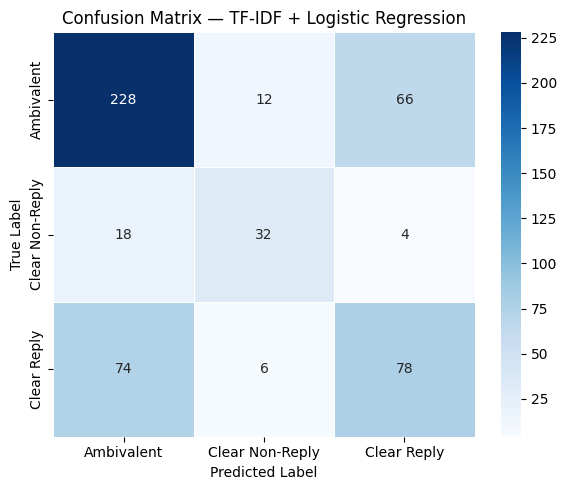

  Word2Vec + Logistic Regression

Accuracy : 0.5483

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent     0.6943    0.6013    0.6445       306
Clear Non-Reply     0.3488    0.5556    0.4286        54
    Clear Reply     0.4192    0.4430    0.4308       158

       accuracy                         0.5483       518
      macro avg     0.4874    0.5333    0.5013       518
   weighted avg     0.5744    0.5483    0.5568       518



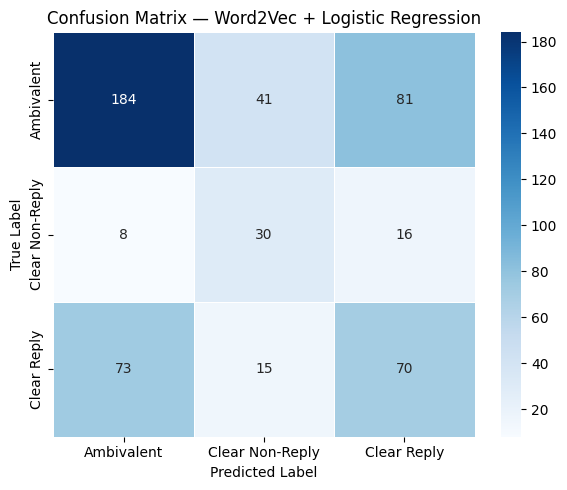

In [32]:
# ============================================================
# 5.4 Full Evaluation — Classification Reports + Confusion Matrices
# ------------------------------------------------------------
# Evaluate the best validation-selected models on val_split
# using the assignment's required classification metrics.
# ============================================================

CLASS_NAMES = ["Ambivalent", "Clear Non-Reply", "Clear Reply"]

def evaluate_model(model, X_val, y_val, model_name):
    y_pred = model.predict(X_val)

    print("=" * 60)
    print(f"  {model_name}")
    print("=" * 60)
    print(f"\nAccuracy : {accuracy_score(y_val, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_val, y_pred, target_names=CLASS_NAMES, digits=4))

    # Confusion matrix
    cm = confusion_matrix(y_val, y_pred, labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        linewidths=0.5, ax=ax
    )
    ax.set_title(f"Confusion Matrix — {model_name}", fontsize=12)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    plt.tight_layout()
    fname = model_name.lower().replace(" ", "_").replace("+", "").replace("-", "") + "_confusion_matrix.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

    return y_pred

y_pred_tfidf = evaluate_model(best_tfidf_model, X_val_tfidf, y_val, "TF-IDF + Logistic Regression")
y_pred_w2v = evaluate_model(best_w2v_model, X_val_w2v, y_val, "Word2Vec + Logistic Regression")

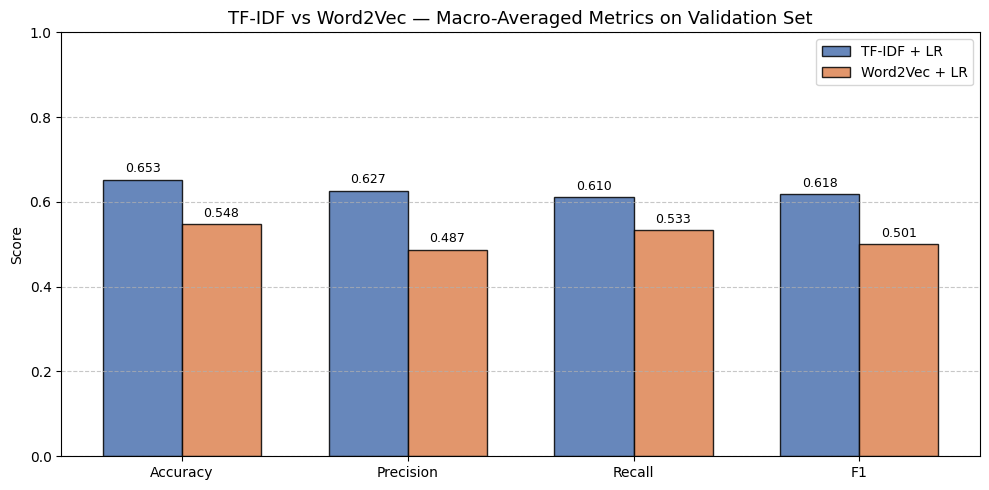


Summary Table:
Metric          TF-IDF + LR  Word2Vec + LR
------------------------------------------
Accuracy             0.6525         0.5483
Precision            0.6265         0.4874
Recall               0.6105         0.5333
F1                   0.6179         0.5013


In [33]:
# ============================================================
# 5.5 Model Comparison — Side-by-Side Metrics
# ------------------------------------------------------------
# Compare TF-IDF and Word2Vec models using macro-averaged metrics
# on the validation set.
# ============================================================

metrics = {
    "TF-IDF + LR": {
        "Accuracy"  : accuracy_score(y_val, y_pred_tfidf),
        "Precision" : precision_score(y_val, y_pred_tfidf, average="macro", zero_division=0),
        "Recall"    : recall_score(y_val, y_pred_tfidf, average="macro", zero_division=0),
        "F1"        : f1_score(y_val, y_pred_tfidf, average="macro", zero_division=0),
    },
    "Word2Vec + LR": {                
        "Accuracy"  : accuracy_score(y_val, y_pred_w2v),
        "Precision" : precision_score(y_val, y_pred_w2v, average="macro", zero_division=0),
        "Recall"    : recall_score(y_val, y_pred_w2v, average="macro", zero_division=0),
        "F1"        : f1_score(y_val, y_pred_w2v, average="macro", zero_division=0),
    }
}

metric_names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# Bar plots for both models
bars1 = ax.bar(x - width/2, [metrics["TF-IDF + LR"][m] for m in metric_names],
               width, label="TF-IDF + LR", color="#4C72B0", edgecolor="black", alpha=0.85)

bars2 = ax.bar(x + width/2, [metrics["Word2Vec + LR"][m] for m in metric_names], 
               width, label="Word2Vec + LR", color="#DD8452", edgecolor="black", alpha=0.85)  

ax.set_ylabel("Score")
ax.set_title("TF-IDF vs Word2Vec — Macro-Averaged Metrics on Validation Set", fontsize=13)  
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.0)
ax.legend()
ax.yaxis.grid(True, linestyle="--", alpha=0.7)

# Annotate bar values
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("model_comparison_bar.png", dpi=150, bbox_inches="tight")
plt.show()

# Tabular summary of metrics
print("\nSummary Table:")
print(f"{'Metric':<12} {'TF-IDF + LR':>14} {'Word2Vec + LR':>14}")   
print("-" * 42)
for m in metric_names:
    print(f"{m:<12} {metrics['TF-IDF + LR'][m]:>14.4f} {metrics['Word2Vec + LR'][m]:>14.4f}")

## 6. Results, Analysis and Submission

This section presents the final comparison between the TF-IDF and Word2Vec models.

We analyse performance using multiple metrics and diagnostic plots, including per-class results, common error patterns, learning curves, and other evaluation visualisations. Based on these results, we select the best-performing model and generate predictions for Kaggle submission.

In [34]:
# ============================================================
# 6.1 Qualitative Error Analysis (TF-IDF)
# ------------------------------------------------------------
# Inspect representative validation errors from the best TF-IDF
# model, including confidence-based mistakes and common confusion
# types.
# ============================================================

# Recompute validation predictions if needed
try:
    y_pred_tfidf
except NameError:
    y_pred_tfidf = best_tfidf_model.predict(X_val_tfidf)

# Predicted probabilities for confidence-based analysis
val_proba_tfidf = best_tfidf_model.predict_proba(X_val_tfidf)
proba_df = pd.DataFrame(val_proba_tfidf, columns=best_tfidf_model.classes_)

# Local dataframe aligned with validation rows
error_df = val_split.copy().reset_index(drop=True)

# True and predicted labels
error_df["true_label"] = list(y_val)
error_df["pred_label"] = list(y_pred_tfidf)

# Confidence assigned to the predicted class
pred_conf = []
for i, pred in enumerate(y_pred_tfidf):
    pred_conf.append(proba_df.loc[i, pred])
error_df["pred_confidence"] = pred_conf

# Text length features for inspection
error_df["question_len"] = error_df["question_clean"].fillna("").str.split().str.len()
error_df["answer_len"]   = error_df["answer_clean"].fillna("").str.split().str.len()

# Error flag
error_df["is_error"] = error_df["true_label"] != error_df["pred_label"]

# Helper printer
def print_example(row, title):
    print("=" * 100)
    print(title)
    print("=" * 100)
    print(f"True label      : {row['true_label']}")
    print(f"Predicted label : {row['pred_label']}")
    print(f"Confidence      : {row['pred_confidence']:.4f}")
    print(f"Question length : {row['question_len']}")
    print(f"Answer length   : {row['answer_len']}")
    print("-" * 100)
    print("QUESTION:")
    print(row["question"])
    print("-" * 100)
    print("ANSWER:")
    print(row["interview_answer"])
    print("-" * 100)
    print("CLEAN QUESTION:")
    print(row["question_clean"])
    print("-" * 100)
    print("CLEAN ANSWER:")
    print(row["answer_clean"])
    print()

# 1) False positive Clear Non-Reply
fp_cnr = error_df[
    (error_df["pred_label"] == "Clear Non-Reply") &
    (error_df["true_label"] != "Clear Non-Reply")
].sort_values("pred_confidence", ascending=False)

if len(fp_cnr) > 0:
    print_example(fp_cnr.iloc[0], "EXAMPLE 1 — FALSE POSITIVE: predicted Clear Non-Reply")
else:
    print("No false positive Clear Non-Reply example found.\n")

# 2) False negative Clear Reply
fn_cr = error_df[
    (error_df["true_label"] == "Clear Reply") &
    (error_df["pred_label"] != "Clear Reply")
].sort_values("pred_confidence", ascending=False)

if len(fn_cr) > 0:
    print_example(fn_cr.iloc[0], "EXAMPLE 2 — FALSE NEGATIVE: true Clear Reply but predicted something else")
else:
    print("No false negative Clear Reply example found.\n")

# 3) Ambivalent-related confusion
amb_conf = error_df[
    ((error_df["true_label"] == "Ambivalent") & (error_df["pred_label"] != "Ambivalent")) |
    ((error_df["pred_label"] == "Ambivalent") & (error_df["true_label"] != "Ambivalent"))
].sort_values("pred_confidence", ascending=False)

if len(amb_conf) > 0:
    print_example(amb_conf.iloc[0], "EXAMPLE 3 — AMBIVALENT CONFUSION")
else:
    print("No Ambivalent confusion example found.\n")

# 4) Highest-confidence mistakes overall
top_errors = error_df[error_df["is_error"]].sort_values("pred_confidence", ascending=False).head(10)

print("=" * 100)
print("TOP 10 HIGHEST-CONFIDENCE TF-IDF ERRORS")
print("=" * 100)

if len(top_errors) > 0:
    display(
        top_errors[[
            "true_label", "pred_label", "pred_confidence",
            "question_len", "answer_len",
            "question", "interview_answer"
        ]]
    )
else:
    print("No validation errors found.")

# 5) Confusion-type summary
conf_summary = (
    error_df[error_df["is_error"]]
    .groupby(["true_label", "pred_label"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print("\n" + "=" * 100)
print("ERROR TYPE SUMMARY (true_label -> pred_label)")
print("=" * 100)
display(conf_summary)

EXAMPLE 1 — FALSE POSITIVE: predicted Clear Non-Reply
True label      : Ambivalent
Predicted label : Clear Non-Reply
Confidence      : 0.8167
Question length : 15
Answer length   : 36
----------------------------------------------------------------------------------------------------
QUESTION:
What should Americans expect from Congress as it relates to abortion rights after the midterms?
----------------------------------------------------------------------------------------------------
ANSWER:
I don't think they can expect much of anything other than, we're going to maintain our positions.I'm not going to get into more questions. I shouldn't even have answered your question.
----------------------------------------------------------------------------------------------------
CLEAN QUESTION:
what should americans expect from congress as it relates to abortion rights after the midterms
----------------------------------------------------------------------------------------------------
CL

,true_label,pred_label,pred_confidence,question_len,answer_len,question,interview_answer
424,Ambivalent,Clear Non-Reply,0.816700,15,36,What should Americans expect from Congress as ...,I don't think they can expect much of anything...
68,Ambivalent,Clear Non-Reply,0.814365,12,15,Are you still going to sign the Executive orde...,You will answer—you'll ask me that question a ...
337,Clear Non-Reply,Ambivalent,0.750422,28,518,"Prime Minister Harper, you seemed to suggest ...","First of all, any effort to try to try--tie Ke..."
138,Clear Reply,Ambivalent,0.743386,12,682,Isn't consumer spending or overspending how w...,"Well, first of all, I don't think it's accurat..."
401,Clear Reply,Ambivalent,0.734427,35,467,What kind of assurances could you give Chancel...,It's not quite accurate to say that the U.S. G...
283,Clear Reply,Ambivalent,0.732337,18,767,Did President Putin correctly predict that Pr...,"First of all, I absolutely would save Mr. Puti..."
76,Clear Reply,Clear Non-Reply,0.722817,20,82,Are you prepared to sign off on the Oracle and...,"Okay, they're giving me studies on the deal. I..."
399,Clear Reply,Ambivalent,0.720426,14,314,Do you think it's time for tough U.N. sanction...,"As you know, we have been discussing this issu..."
372,Clear Reply,Ambivalent,0.707412,19,524,What does it feel like to see setbacks for th...,It feels bad. [] The toughest thing over the l...
234,Clear Reply,Ambivalent,0.707168,5,210,"Anything sanctions on Russia, sir?","Yes, we'll do sanctions. As soon as they very ..."



ERROR TYPE SUMMARY (true_label -> pred_label)


,true_label,pred_label,count
4,Clear Reply,Ambivalent,74
1,Ambivalent,Clear Reply,66
2,Clear Non-Reply,Ambivalent,18
0,Ambivalent,Clear Non-Reply,12
5,Clear Reply,Clear Non-Reply,6
3,Clear Non-Reply,Clear Reply,4


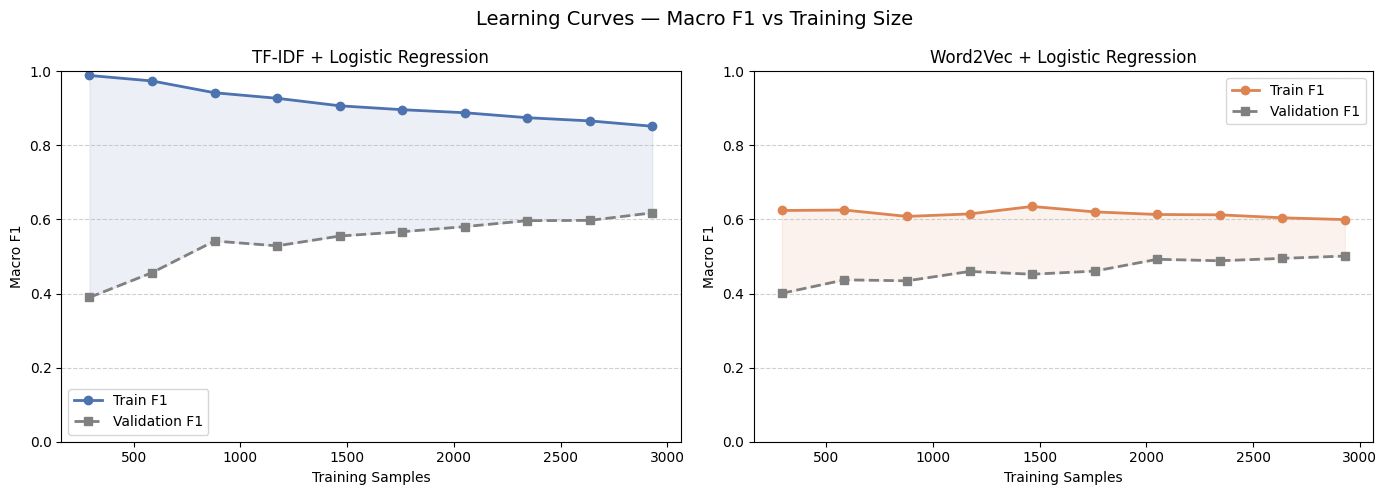

Learning curves generated successfully.
Original best_tfidf_model and best_w2v_model were not modified.


In [35]:
# ============================================================
# 6.2 Learning Curves — Overfitting / Underfitting Check
# ------------------------------------------------------------
# This cell analyses train vs validation macro-F1 as training
# size increases, to assess overfitting and underfitting.
# Cloned estimators are used so the original best models are
# not modified.
# ============================================================

def plot_learning_curve(model, X_train, y_train, X_val, y_val):
    """
    Train cloned models on increasing stratified subsets of the
    training data and evaluate macro-F1 on both the subset and
    the full validation split.
    """
    train_fracs = np.linspace(0.1, 1.0, 10)
    n_train = len(y_train)

    train_f1s, val_f1s = [], []

    for frac in train_fracs:
        n = max(int(frac * n_train), 10)

        if frac < 1.0:
            sss = StratifiedShuffleSplit(n_splits=1, train_size=n, random_state=SEED)
            idx, _ = next(sss.split(np.zeros(n_train), y_train))
            X_sub = X_train[idx]
            y_sub = y_train[idx]
        else:
            X_sub, y_sub = X_train, y_train

        # Clone the model to keep the original estimator unchanged
        model_i = clone(model)
        model_i.fit(X_sub, y_sub)

        # Training performance on the fitted subset
        y_pred_tr = model_i.predict(X_sub)
        train_f1s.append(
            f1_score(y_sub, y_pred_tr, average="macro", zero_division=0)
        )

        # Validation performance on the full hold-out split
        y_pred_v = model_i.predict(X_val)
        val_f1s.append(
            f1_score(y_val, y_pred_v, average="macro", zero_division=0)
        )

    return np.array(train_fracs) * n_train, train_f1s, val_f1s


fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Learning Curves — Macro F1 vs Training Size", fontsize=14)

configs = [
    (best_tfidf_model, X_train_tfidf, X_val_tfidf, "TF-IDF + Logistic Regression", "#4C72B0", axes[0]),
    (best_w2v_model,   X_train_w2v,   X_val_w2v,   "Word2Vec + Logistic Regression", "#DD8452", axes[1]),
]

for model, X_tr, X_v, name, color, ax in configs:
    sizes, tr_f1, v_f1 = plot_learning_curve(model, X_tr, y_train, X_v, y_val)

    ax.plot(sizes, tr_f1, "o-", color=color, label="Train F1", linewidth=2)
    ax.plot(sizes, v_f1, "s--", color="gray", label="Validation F1", linewidth=2)
    ax.fill_between(sizes, tr_f1, v_f1, alpha=0.1, color=color)

    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Training Samples")
    ax.set_ylabel("Macro F1")
    ax.set_ylim(0, 1.0)
    ax.legend()
    ax.yaxis.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print("Learning curves generated successfully.")
print("Original best_tfidf_model and best_w2v_model were not modified.")

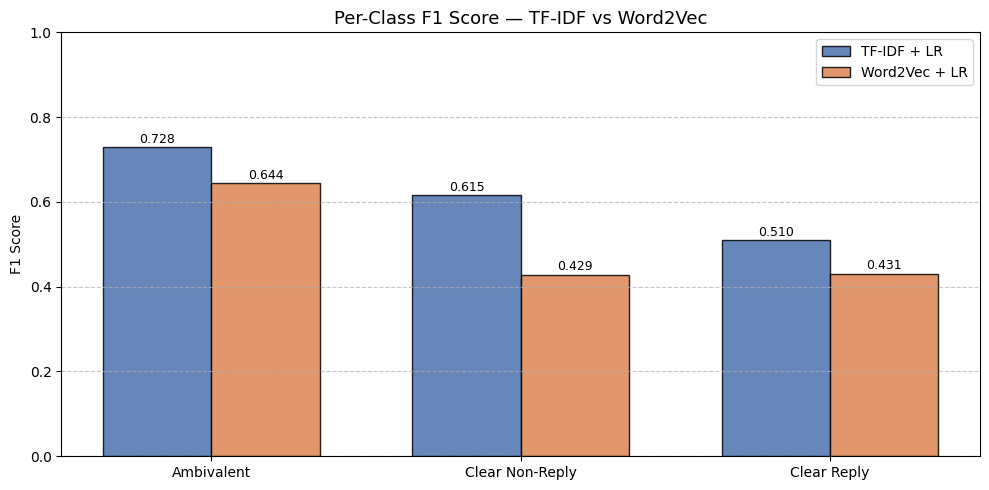

Per-class F1:
  Ambivalent           TF-IDF=0.7284  Word2Vec=0.6445
  Clear Non-Reply      TF-IDF=0.6154  Word2Vec=0.4286
  Clear Reply          TF-IDF=0.5098  Word2Vec=0.4308


In [36]:
# ============================================================
# 6.3 Per-Class F1 Comparison
# ------------------------------------------------------------
# Compare per-class F1 scores for both models, highlighting
# differences that may be hidden by macro-averaged metrics.
# ============================================================

per_class_tfidf = f1_score(y_val, y_pred_tfidf, average=None, labels=CLASS_NAMES, zero_division=0)
per_class_w2v   = f1_score(y_val, y_pred_w2v,   average=None, labels=CLASS_NAMES, zero_division=0)

x = np.arange(len(CLASS_NAMES))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# Bar plots for each model
bars1 = ax.bar(x - width/2, per_class_tfidf, width, label="TF-IDF + LR",
               color="#4C72B0", edgecolor="black", alpha=0.85)

bars2 = ax.bar(x + width/2, per_class_w2v,   width, label="Word2Vec + LR",
               color="#DD8452", edgecolor="black", alpha=0.85)

ax.set_ylabel("F1 Score")
ax.set_title("Per-Class F1 Score — TF-IDF vs Word2Vec", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.0)
ax.legend()
ax.yaxis.grid(True, linestyle="--", alpha=0.7)

# Annotate bar values
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", fontsize=9)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

# Print per-class scores
print("Per-class F1:")
for cls, f1_t, f1_w in zip(CLASS_NAMES, per_class_tfidf, per_class_w2v):
    print(f"  {cls:<20} TF-IDF={f1_t:.4f}  Word2Vec={f1_w:.4f}")

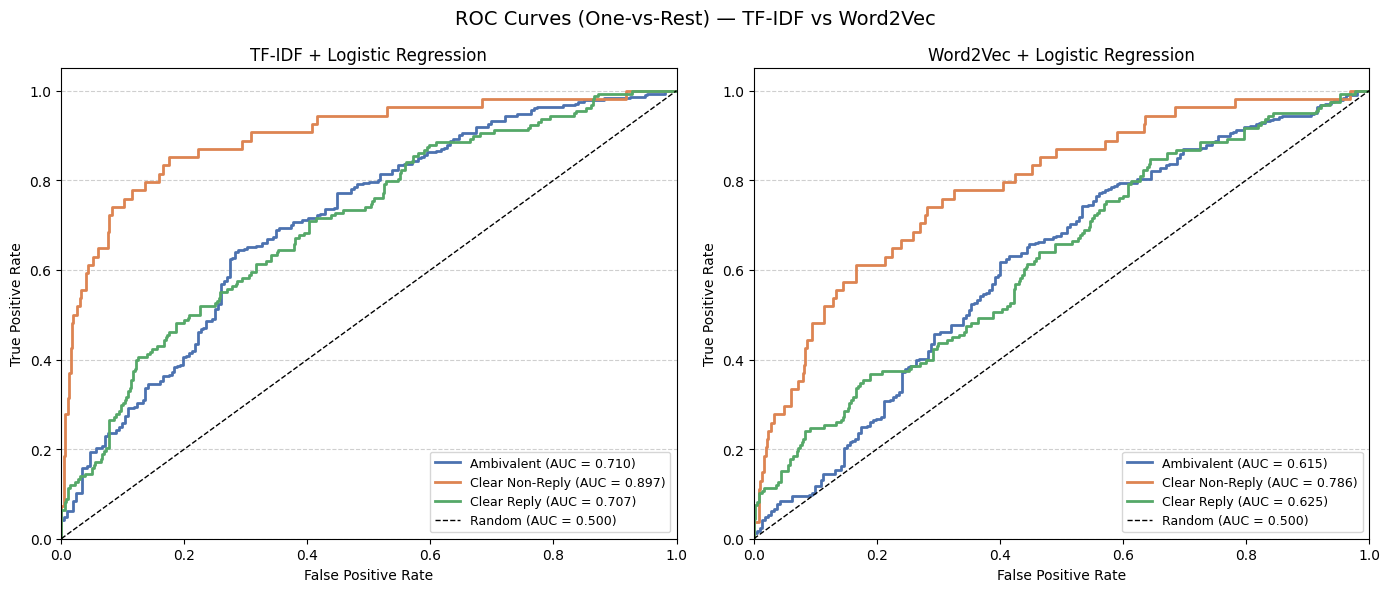

Class                    TF-IDF AUC   Word2Vec AUC
-------------------------------------------------------
Ambivalent                   0.7096         0.6153
Clear Non-Reply              0.8967         0.7864
Clear Reply                  0.7066         0.6249


In [37]:
# ============================================================
# 6.4 ROC Curves — One-vs-Rest Comparison
# ------------------------------------------------------------
# Plot ROC curves using a one-vs-rest setup for each class.
# AUC measures how well each class is separated from the rest.
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Binarize labels for OvR ROC computation
y_val_bin = label_binarize(y_val, classes=CLASS_NAMES)

# Probability scores required for ROC curves
proba_tfidf = best_tfidf_model.predict_proba(X_val_tfidf)
proba_w2v   = best_w2v_model.predict_proba(X_val_w2v)

# ---- Plot ----
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("ROC Curves (One-vs-Rest) — TF-IDF vs Word2Vec", fontsize=14)

colors = ["#4C72B0", "#DD8452", "#55A868"]

for ax, proba, model_name in zip(
    axes,
    [proba_tfidf, proba_w2v],
    ["TF-IDF + Logistic Regression", "Word2Vec + Logistic Regression"]
):
    for i, (cls, color) in enumerate(zip(CLASS_NAMES, colors)):
        fpr, tpr, _ = roc_curve(y_val_bin[:, i], proba[:, i])
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, linewidth=2,
                label=f"{cls} (AUC = {roc_auc:.3f})")

    # Random baseline
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random (AUC = 0.500)")

    ax.set_title(model_name, fontsize=12)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.legend(loc="lower right", fontsize=9)
    ax.yaxis.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- AUC summary table ----
print("=" * 55)
print(f"{'Class':<20} {'TF-IDF AUC':>14} {'Word2Vec AUC':>14}")
print("-" * 55)
for i, cls in enumerate(CLASS_NAMES):
    fpr_t, tpr_t, _ = roc_curve(y_val_bin[:, i], proba_tfidf[:, i])
    fpr_w, tpr_w, _ = roc_curve(y_val_bin[:, i], proba_w2v[:, i])
    auc_t = auc(fpr_t, tpr_t)
    auc_w = auc(fpr_w, tpr_w)
    print(f"{cls:<20} {auc_t:>14.4f} {auc_w:>14.4f}")
print("=" * 55)

In [38]:
# ============================================================
# 6.5 Final TF-IDF Model + Kaggle Submission
# ------------------------------------------------------------
# This cell:
# (1) Reports the validation performance of the selected TF-IDF model
# (2) Retrains the same configuration on all training data
#     and generates submission.csv
#
# The validation score remains the primary evaluation metric.
# ============================================================

# ------------------------------------------------------------
# PART A — Validation evaluation
# ------------------------------------------------------------
best_tfidf_model = LogisticRegression(
    C=best_C_tfidf,
    penalty=best_penalty_tfidf,
    solver=best_solver_tfidf,
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED,
    multi_class="multinomial"
)

best_tfidf_model.fit(X_train_tfidf, y_train)
y_val_pred_clean = best_tfidf_model.predict(X_val_tfidf)

val_accuracy  = accuracy_score(y_val, y_val_pred_clean)
val_precision = precision_score(y_val, y_val_pred_clean, average="macro", zero_division=0)
val_recall    = recall_score(y_val, y_val_pred_clean, average="macro", zero_division=0)
val_f1        = f1_score(y_val, y_val_pred_clean, average="macro", zero_division=0)

print("=" * 70)
print("BEST SINGLE-SPLIT TF-IDF + LOGISTIC REGRESSION")
print("=" * 70)
print("Vectorizer params:", TFIDF_PARAMS)
print(f"C={best_C_tfidf}, penalty={best_penalty_tfidf}, solver={best_solver_tfidf}")
print(f"Accuracy        : {val_accuracy:.4f}")
print(f"Macro Precision : {val_precision:.4f}")
print(f"Macro Recall    : {val_recall:.4f}")
print(f"Macro F1        : {val_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_clean, digits=4))

print("\nConfusion Matrix (rows=true, cols=pred):")
print(confusion_matrix(y_val, y_val_pred_clean, labels=CLASS_NAMES))

# ------------------------------------------------------------
# PART B — Final training + submission
# ------------------------------------------------------------
# Retrain using all available training data with the same
# preprocessing and hyperparameters.

tfidf_vectorizer_final = TfidfVectorizer(**TFIDF_PARAMS)

X_all_tfidf = tfidf_vectorizer_final.fit_transform(train_df["input_tfidf"])
X_test_tfidf_final = tfidf_vectorizer_final.transform(test_df["input_tfidf"])
y_all = train_df["clarity_label"].values

final_tfidf_model = LogisticRegression(
    C=best_C_tfidf,
    penalty=best_penalty_tfidf,
    solver=best_solver_tfidf,
    class_weight="balanced",
    max_iter=2000,
    random_state=SEED,
    multi_class="multinomial"
)

final_tfidf_model.fit(X_all_tfidf, y_all)
y_test_pred_final = final_tfidf_model.predict(X_test_tfidf_final)

print("\n" + "=" * 70)
print("FINAL MODEL TRAINED ON ALL TRAINING DATA")
print("=" * 70)
print(f"Training samples used: {len(y_all)}")
print("Test prediction distribution:")
print(pd.Series(y_test_pred_final).value_counts())

# Create submission file
submission = pd.DataFrame({
    "Id": range(len(y_test_pred_final)),
    "Predicted": y_test_pred_final
})

submission.to_csv("submission.csv", index=False)

print("\nsubmission.csv saved successfully.")
print(submission.head(10))

BEST SINGLE-SPLIT TF-IDF + LOGISTIC REGRESSION
Vectorizer params: {'ngram_range': (1, 3), 'max_features': 120000, 'min_df': 2, 'sublinear_tf': True}
C=1.5, penalty=l2, solver=lbfgs
Accuracy        : 0.6525
Macro Precision : 0.6265
Macro Recall    : 0.6105
Macro F1        : 0.6179

Classification Report:
                 precision    recall  f1-score   support

     Ambivalent     0.7125    0.7451    0.7284       306
Clear Non-Reply     0.6400    0.5926    0.6154        54
    Clear Reply     0.5270    0.4937    0.5098       158

       accuracy                         0.6525       518
      macro avg     0.6265    0.6105    0.6179       518
   weighted avg     0.6484    0.6525    0.6500       518


Confusion Matrix (rows=true, cols=pred):
[[228  12  66]
 [ 18  32   4]
 [ 74   6  78]]

FINAL MODEL TRAINED ON ALL TRAINING DATA
Training samples used: 3448
Test prediction distribution:
Ambivalent         204
Clear Reply         90
Clear Non-Reply     14
Name: count, dtype: int64

submissio